<h2 align = 'center'> Brazilian E-Commerce Public Dataset by Olist </h2>
<div align="center"> 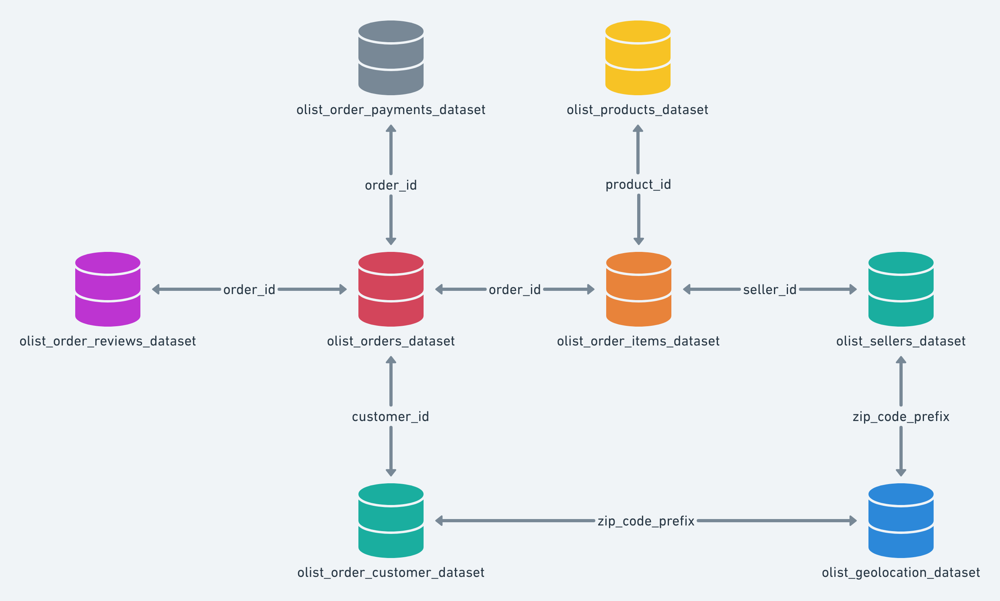 </div>


<div align="center"> <img src="https://storage.googleapis.com/kaggle-datasets-images/55151/105464/d59245a7014a35a35cc7f7b721de4dae/dataset-cover.png?t=2018-09-21-16-21-21" alt="Centered image"> </div>

Добро пожаловать! Это общедоступный бразильский набор данных о заказах, сделанных в интернет-магазине Olist. В наборе данных содержится информация о 100 000 заказов, сделанных с 2016 по 2018 год на различных торговых площадках Бразилии. С его помощью можно просмотреть заказ в разных аспектах: от статуса заказа, цены, оплаты и доставки до местоположения покупателя, характеристик товара и, наконец, отзывов покупателей. Мы также опубликовали набор данных с геолокацией, в котором бразильские почтовые индексы сопоставлены с координатами широты и долготы.

In [1]:
#Библиотеки для EDA
import duckdb
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from cycler import cycler

#ML
import optuna
from imblearn.under_sampling import RandomUnderSampler

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    KFold,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

#Metrics
from sklearn.metrics import (
    precision_score,
    f1_score,
    roc_auc_score, 
    average_precision_score,
    recall_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

Импортирование библиотек

In [2]:
warnings.filterwarnings('ignore')
TEST_SIZE = 0.25
RANDOM_STATE = 42
BURN_IN_MONTHS = 3
HORIZON_MONTHS = 6
cv=KFold(shuffle=True,n_splits=5,random_state=RANDOM_STATE)

#colors
colormap = sns.diverging_palette(220, 10, as_cmap = True)
colorbox = [
    "#fb4934",  # Красный
    "#fabd2f",  # Желтый
    "#b8bb26",  # Зеленый
    "#83a598",  # Голубой
    "#d3869b",  # Фиолетовый
    "#fe8019",  # Ораньжевый
    "#8ec07c",  # Бирюзовый
]

rc = {
    "axes.facecolor": "#282828",
    "figure.facecolor": "#282828",
    "axes.edgecolor": "#3c3836",
    "grid.color": "#504945",
    "axes.labelcolor": "#ebdbb2",
    "xtick.color": "#d5c4a1",
    "ytick.color": "#d5c4a1",
    "grid.alpha": 0.3,
    "axes.prop_cycle": cycler(color=colorbox),
    "legend.facecolor": "#DCDCDC",
    "text.color": "ebdbb2", 
    "axes.titlecolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "legend.labelcolor": "white",
    "legend.title_fontsize": 12,
}

sns.set(rc=rc, style="darkgrid")
# Устанавливаем настройку rc и стиль "darkgrid" seaborn


palette_sex={"female" : "#c90076", "male": "#2986CC"}
palette_surv = {0: "#00ffff", 1: "#ff0000"}

Константы

In [3]:
#Функция для визуализации EDA графиков: гистограмма, boxplot
def num_plot(data,column_list,bins=50,figsize=(6,3)):
    for column in column_list:
        plt.figure(figsize=(figsize))
        # Первый subplot - ГИСТОГРАММА
        plt.subplot(1,2,1)
        sns.histplot(data=data,x=column,kde=True,bins=bins, palette=colorbox, alpha=0.7)
        plt.title(f'Гистограмма частоты {column} относительно целевой переменной',color='white')
        plt.xlabel(f'Значения {column}',color='white')
        plt.ylabel('Частота',color='white')
        plt.grid()
        # Второй subplot - BOXPLOT
        plt.subplot(1,2,2)
        sns.boxplot(data=data,y=column, palette=colorbox)
        plt.title(f'Boxplot {column}',color='white')
        plt.xlabel('Boxplot',color='white')
        plt.ylabel('Значения',color='white')
        plt.grid()
        plt.show()

#Функция визуализации pie charm
def pie_charm(series,title='',colors=[colorbox[0],colorbox[1]]):
    vc_series = series.value_counts()
    values = vc_series.values
    index = list(vc_series.index)
    plt.figure(figsize=(14, 7))
    plt.pie(
        values,
        labels=index,
        startangle=90, frame=True, radius=1.3,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12, 'weight': 'bold'},
        autopct='%1.1f%%',
        colors=colors,
    )
    plt.legend()
    plt.title(title,color='white')
    plt.show()

#Функция для визуализации EDA графиков: countplot
def count_plot(data,column_list,figsize=(9,3),palette=colorbox, rotation=90):
    for column in column_list:
        plt.figure(figsize=figsize)
        sns.countplot(data=data,x=column,palette=colorbox)
        plt.title(f'Количество {column}',color='white')
        plt.xlabel('Значения',color='white')
        plt.ylabel('Количество значений',color='white')
        plt.xticks(fontsize=7,rotation=rotation)
        plt.show()

#Функция визуализации линейной зависимости
def plotlm(data, x_var, y_var, row_var=None, target=None):
    plt.figure(figsize=(14,7))
    lm = sns.lmplot(
        data=data,
        x=x_var,
        y=y_var,
        row=row_var,
        hue = row_var,
        lowess=True,
        height=2,
        aspect=4,
        palette=palette_sex ,
        col=target,
        line_kws={"color": "white"},
        scatter_kws={"alpha": 0.3},
    )
    for ax in lm.axes.flatten():
        ax.tick_params(color='white')
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")

        lm.set_titles(
            col_template="Target value:{col_name}",
            color="white",
            size=12,
            weight="bold"
    )
    plt.suptitle(
        f"{x_var.replace('_', ' ').title()} VS {y_var.replace('_', ' ').title()} by Target Variable",
        y=1.02,
        fontsize=16,color='white',
    )
    plt.tight_layout()
    plt.show()

#lift метрика
def lift_at_k(y_true, y_proba, k=0.1):
    n = len(y_true)
    top_k_idx = np.argsort(y_proba)[::-1][:int(n * k)]
    return pd.Series(y_true).iloc[top_k_idx].mean() / pd.Series(y_true).mean()

#Метрики для быстрой оценки качества
def model_metrics(y_true, y_pred, y_proba):
    roc = roc_auc_score(y_true, y_proba)
    pr = average_precision_score(y_true, y_proba)
    gini = 2 * roc - 1
    lift10 = lift_at_k(y_true, y_proba, 0.1)
    lift20 = lift_at_k(y_true, y_proba, 0.2)
    print(f'ROC-AUC : {roc:.4f}')
    print(f'PR-AUC  : {pr:.4f}')
    print(f'Gini    : {gini:.4f}')
    print(f'Lift@10 : {lift10:.4f}')
    print(f'Lift@20 : {lift20:.4f}')
    print(f'Recall  : {recall_score(y_true, y_pred):.4f}')

#Подбор порога
def threshold_report(y_true, y_proba, thresholds=(0.5, 0.4, 0.3, 0.2, 0.1)):
    print(f'{"Threshold":<10} {"F1":<10} {"Recall":<10} {"Precision":<10}')

    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)

        print(f'{t:<10.2f}'
              f'{f1_score(y_true, y_pred):<10.3f}'
              f'{recall_score(y_true, y_pred):<10.3f}'
              f'{precision_score(y_true, y_pred, zero_division=0):<10.3f}')

Функции

# Загрузка данных и первичный анализ

In [4]:
olist_customers = pd.read_csv('datasets/olist/olist_customers_dataset.csv')
olist_geo = pd.read_csv('datasets/olist/olist_geolocation_dataset.csv')
olist_order_items = pd.read_csv('datasets/olist/olist_order_items_dataset.csv')
olist_order_payments = pd.read_csv('datasets/olist/olist_order_payments_dataset.csv')
olist_order_reviews = pd.read_csv('datasets/olist/olist_order_reviews_dataset.csv')
olist_orders = pd.read_csv('datasets/olist/olist_orders_dataset.csv')
olist_products = pd.read_csv('datasets/olist/olist_products_dataset.csv')
olist_sellers = pd.read_csv('datasets/olist/olist_sellers_dataset.csv')
product_cat_name_translation = pd.read_csv('datasets/olist/product_category_name_translation.csv')

#### olist_customers

* customer_id - идентификатор, используемый для связи с заказами. Каждому заказу присваивается уникальный customer_id.
* customer_unique_id - уникальный идентификатор клиента. Поскольку один и тот же покупатель получает новый customer_id для каждого нового заказа, это поле позволяет отслеживать повторные покупки. Без него каждый заказ выглядел бы как сделанный новым клиентом.
* customer_zip_code_prefix - первые пять цифр почтового индекса.
* customer_city - город проживания клиента.
* customer_state - штат проживания клиента.

In [5]:
olist_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
olist_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [7]:
print(f"Наличие явных дубликатов в датасете 'olist_customers': {olist_customers.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_customers': {olist_customers[['customer_unique_id','customer_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_customers': 0
Наличие неявных дубликатов в датасете 'olist_customers': 0


Таблица olist_customers содержит информацию о клиентах. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [8]:
print('Количество городов клиентов',olist_customers['customer_city'].nunique())
print('Количество штатов клиентов',olist_customers['customer_state'].nunique())

Количество городов клиентов 4119
Количество штатов клиентов 27


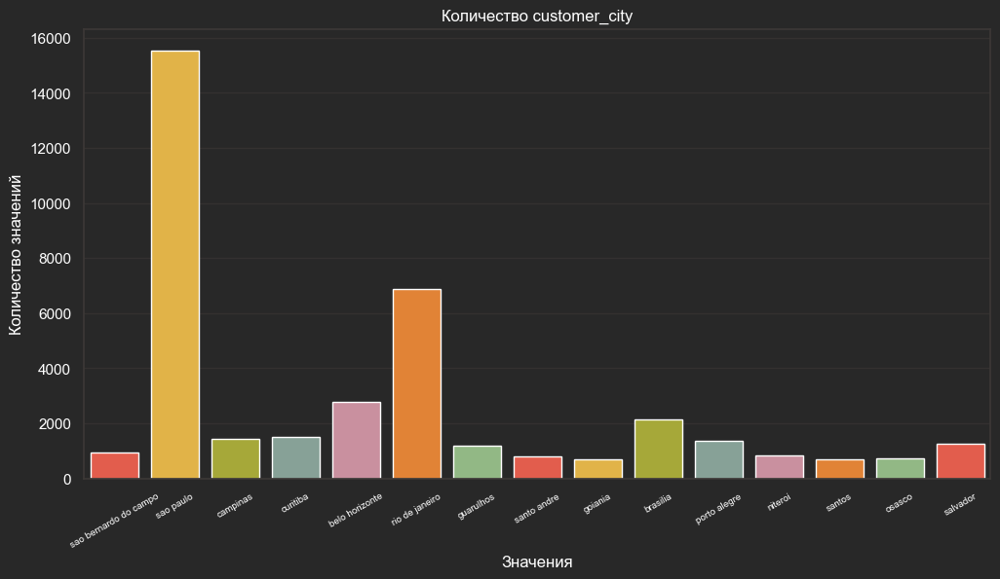

In [9]:
customer_city_names = olist_customers['customer_city'].value_counts().sort_values(ascending=False).index
customer_city_names = customer_city_names[:15]
the_most_frequent_cities = olist_customers.loc[olist_customers['customer_city'].isin(customer_city_names)]
count_plot(the_most_frequent_cities, ['customer_city'], figsize=(12,6), rotation=30)

Данные по городам показывают выраженную географическую концентрацию покупателей. Топ-15 городов возглавляет Сан-Паулу с большим отрывом - 15 540 заказов, что примерно в 2.3 раза больше, чем у следующего по популярности Рио-де-Жанейро (6 882). Остальные города уже существенно уступают: Белу-Оризонти (2 773), Бразилиа (2 131) и Куритиба (1 521)

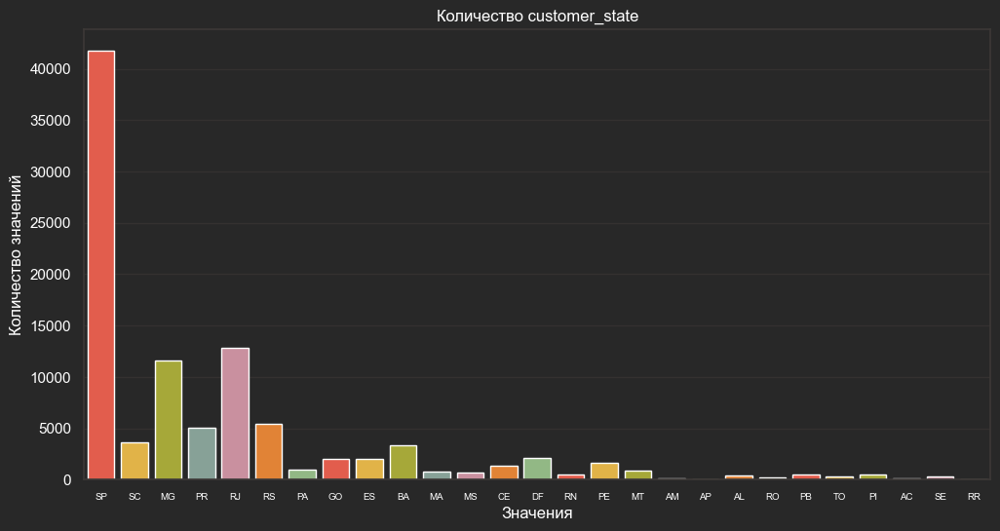

In [10]:
count_plot(olist_customers, ['customer_state'], figsize=(12,6), rotation=0)

На уровне штатов картина аналогичная: штат Сан-Паулу (SP) доминирует с 41 746 заказами - это почти треть всей выборки. За ним следуют Рио-де-Жанейро (RJ, 12 852) и Минас-Жерайс (MG, 11 635). Северные и северо-западные штаты (AM, AC, AP, RR) представлены крайне слабо (менее 200 заказов каждый), что отражает реальную экономическую диспропорцию регионов Бразилии. Для модели это означает потенциальный дисбаланс по географическому признаку, который стоит учесть при fe.

#### olist_geo

* geolocation_zip_code_prefix: первые 5 цифр почтового индекса.
* geolocation_lat: широта
* geolocation_lng: долгота
* geolocation_city: город
* geolocation_state штат

In [11]:
olist_geo.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [12]:
olist_geo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


#### olist_order_items

* order_id: уникальный идентификатор заказа.
* order_item_id: порядковый номер, определяющий количество товаров, включенных в один и тот же заказ.
* product_id: уникальный идентификатор продукта.
* seller_id: уникальный идентификатор продавца.
* shipping_limit_date: показывает дату отправки заказа продавцом логистическому партнеру.
* price: цена товара.
* freight_value: стоимость доставки товара

In [13]:
olist_order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [14]:
olist_order_items.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [15]:
print(f"Наличие явных дубликатов в датасете 'olist_order_items': {olist_order_items.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_items': {olist_order_items[['order_id','seller_id','product_id','order_item_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_items': 0
Наличие неявных дубликатов в датасете 'olist_order_items': 0


Таблица olist_order_items содержит информацию о предметах заказа. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [16]:
olist_order_items['shipping_limit_date'] = pd.to_datetime(
    olist_order_items['shipping_limit_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Тип данных даты и времени был преобразован в верный

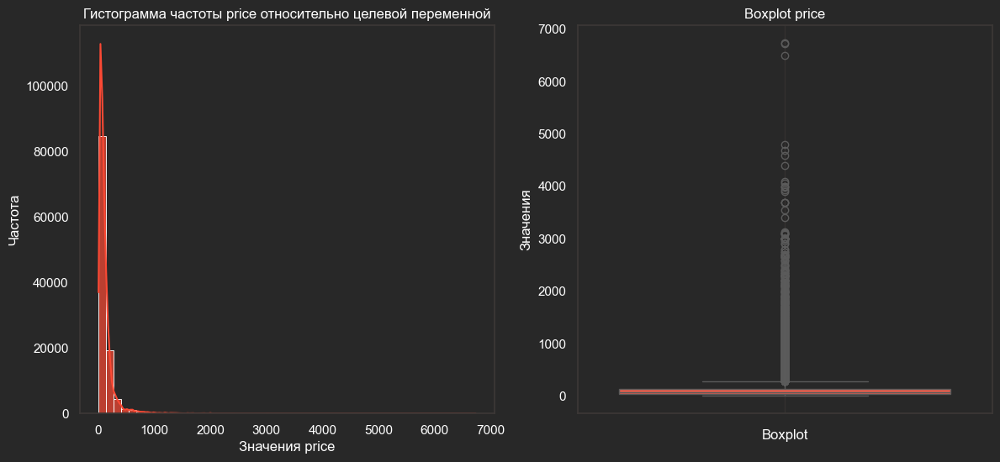

In [17]:
num_plot(olist_order_items,['price'], figsize=(14,6))

In [18]:
olist_order_items['price'].describe()


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Распределение price сильно правосторонне скошено, дорогостоящие товары существенно смещают среднее. Основная масса заказов сосредоточена в диапазоне до 300 единиц, при этом медиана составляет всего 74.99, тогда как среднее - 120.65, что говорит о значительном влиянии выбросов на правом хвосте. Максимальное значение - 6 735, что в ~50 раз превышает медиану. IQR составляет 95 (от 39.90 до 134.90) - 50% заказов укладываются в относительно узкий диапазон недорогих товаров.
Стандартное отклонение 183.63 при среднем 120.65 говорит о крайне высокой дисперсии.

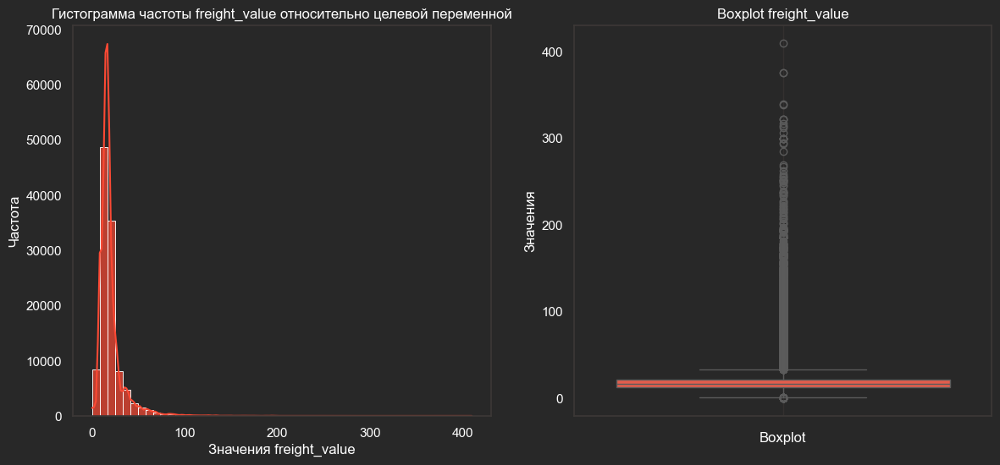

In [19]:
num_plot(olist_order_items,['freight_value'], figsize=(14,6))

In [20]:
olist_order_items['freight_value'].describe()


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

freight_value демонстрирует схожую картину правостороннего скоса, но менее экстремальную. Медиана равна 16.26, среднее - 19.99, IQR от 13.08 до 21.15. Максимум - 409.68, минимум - 0 (бесплатная доставка). Стандартное отклонение 15.81 умеренное относительно среднего, но выбросы присутствуют - боксплот показывает ряд значений в диапазоне от ~200 до ~410, которые, вероятно, соответствуют дорогостоящей доставке в отдалённые регионы

#### olist_order_payments

* order_id: уникальный идентификатор заказа.
* payment_sequential: клиент может оплатить заказ несколькими способами оплаты. Если он это сделает, будет создана последовательность.
* payment_type: способ оплаты, выбранный клиентом.
* payment_installments: количество платежей, выбранных клиентом.
* payment_value: стоимость транзакции.

In [21]:
olist_order_payments.head()


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [22]:
olist_order_payments.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [23]:
print(f"Наличие явных дубликатов в датасете 'olist_order_payments': {olist_order_payments.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_payments': 0


Таблица olist_order_payments содержит информацию о оплате заказов. Пропуски и дубликаты отсутствуют, названия строк соответствуют их содержанию, типы данных определены корректно.

In [24]:
print(f'Уникальные значения признака "payment_sequential":{olist_order_payments.payment_sequential.unique()}')

Уникальные значения признака "payment_sequential":[ 1  2  4  5  3  8  6  7 10 11 17 19 27 12  9 15 13 14 16 25 22 26 29 28
 18 21 24 23 20]


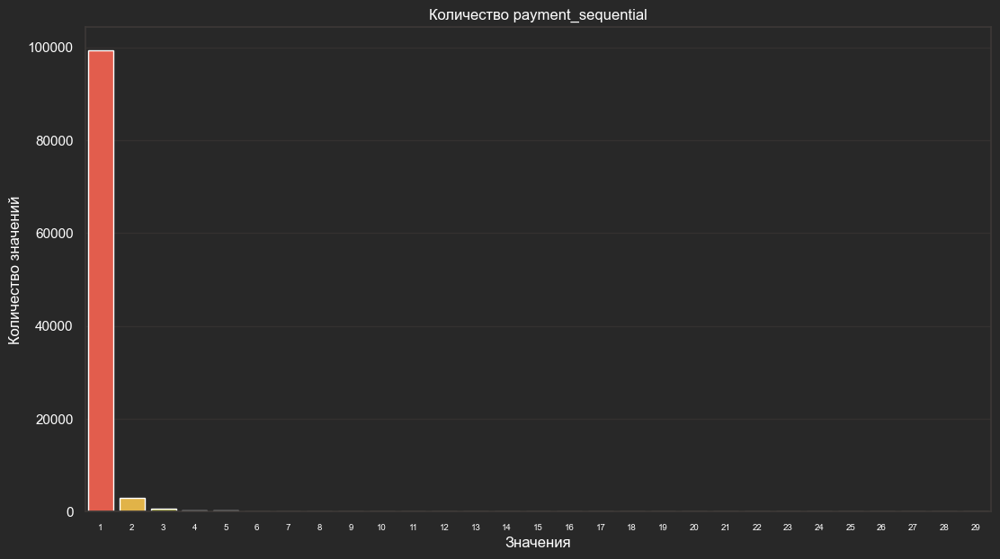

In [25]:
count_plot(olist_order_payments, ['payment_sequential'], figsize=(13,7), rotation=0)

Подавляющее большинство заказов оплачивается за один платёж - 99 360 из ~103 400, то есть около 96%. Два платежа используются уже в 3 039 случаях, а далее частота резко падает. Значения от 10 и выше единичны и могут представлять рассрочку на длительный срок. Признак сильно несбалансирован и в большинстве случаев будет нести мало информации. Возможно стоит трансформировать его в бинарный 1 платёж / более 1 платежа

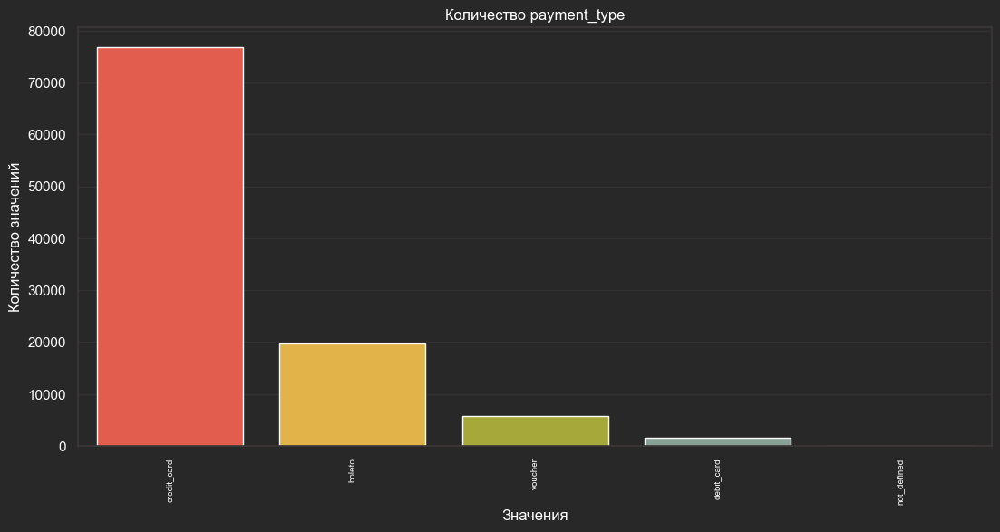

In [26]:
count_plot(olist_order_payments,['payment_type'],figsize=(13,6))

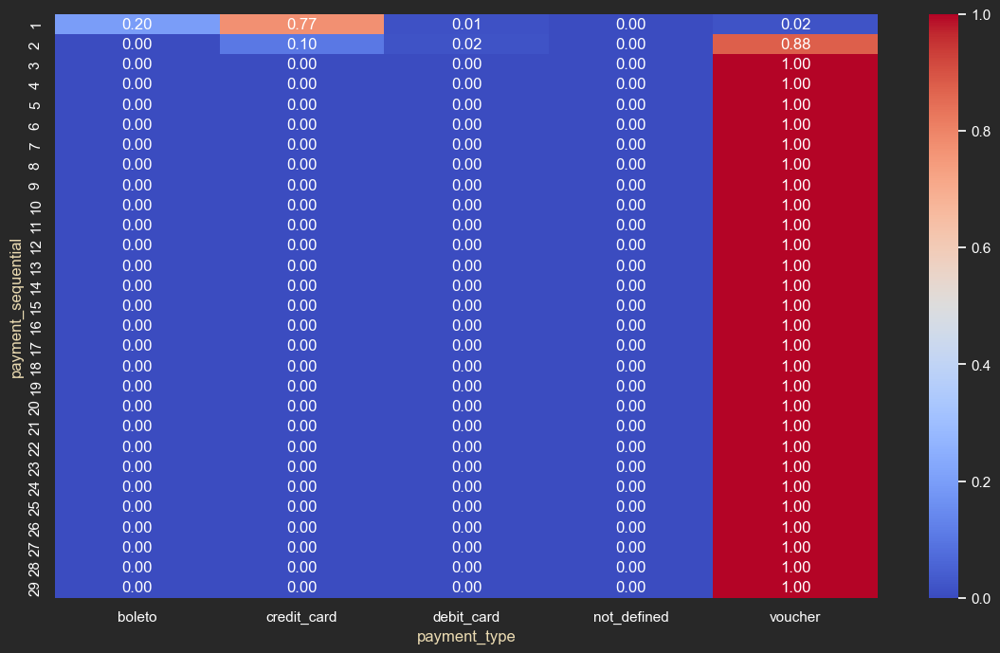

In [27]:
plt.figure(figsize=(14,8))
sns.heatmap(
    pd.crosstab(olist_order_payments['payment_sequential'], olist_order_payments['payment_type'], normalize='index'),
    annot = True,
    cmap = 'coolwarm',
    cbar = True,
    fmt = '.2f'
)
plt.grid()
plt.show()

Тепловая карта соотношения payment_sequential и payment_type выявляет чёткую закономерность: при одном платеже используются все типы оплаты (boleto - 20%, credit_card - 77%, debit_card - 1%, voucher - 2%). Начиная со второго платежа и далее используется только voucher (0.88 и выше, с третьего по двадцать девятый - 1.00)

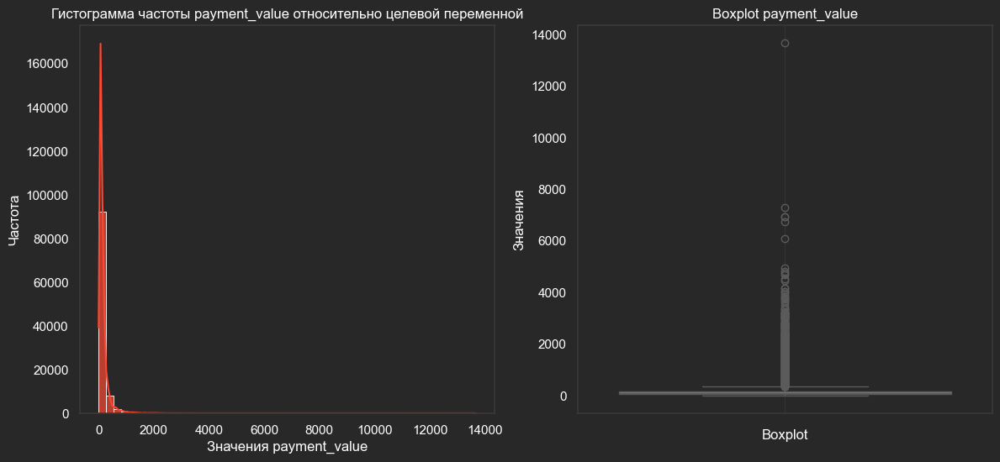

In [28]:
num_plot(olist_order_payments,['payment_value'],figsize=(14,6))

In [29]:
olist_order_payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

#### olist_order_reviews

* review_id: уникальный идентификатор отзыва.
* order_id: уникальный идентификатор заказа.
* review_score: оценка заказа.
* review_comment_title: заголовок комментария.
* review_comment_message: комментарий к отзыву.
* review_creation_date: дата отзыва.
* review_answer_timestamp: дата ответа на отзыв.

In [30]:
olist_order_reviews.head()


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [31]:
olist_order_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [32]:
print(f"Наличие явных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_order_reviews': {olist_order_reviews[['review_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_order_reviews': 0
Наличие неявных дубликатов в датасете 'olist_order_reviews': 0


Таблица olist_order_reviews содержит информацию о отзывах на заказы. В данных содержатся пропуски в признаках текста отзывов, а также в заголовках отзывов. Можно предположить, что люди решили не писать комментарий к отзыву, а лишь оставить оценку заказу. Эта информация не подлежит восстановлению истинных значений, отсутствует более 50% значений, поэтому я решил заполнить пропуски костантным значением, чтобы не терять оценки заказов.

In [33]:
olist_order_reviews.fillna('NaN',inplace=True)

olist_order_reviews['review_creation_date'] = pd.to_datetime(
    olist_order_reviews['review_creation_date']
)
olist_order_reviews['review_answer_timestamp'] = pd.to_datetime(
    olist_order_reviews['review_answer_timestamp']
)

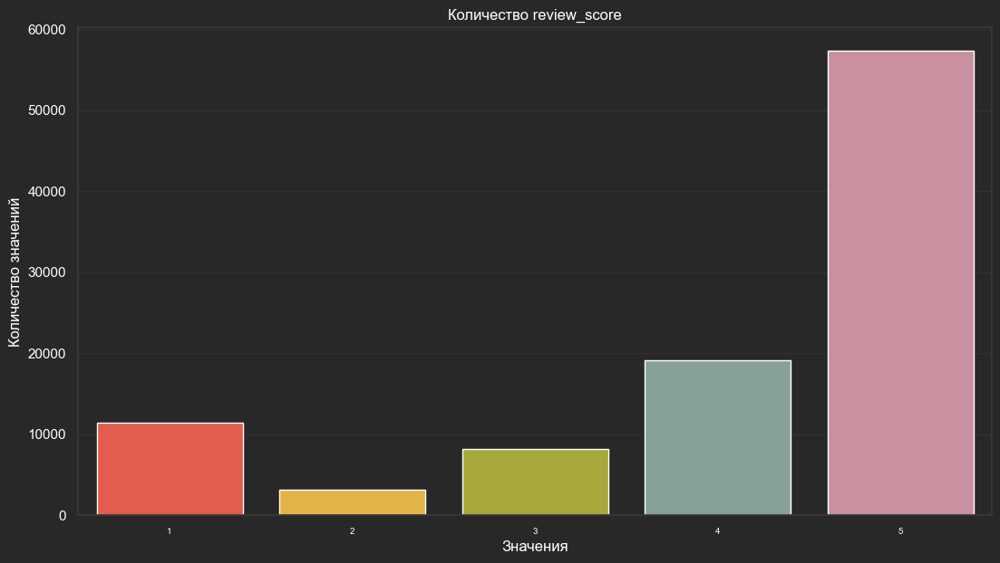

In [34]:
count_plot(olist_order_reviews,['review_score'], figsize=(13,7), rotation=0)

Распределение оценок явно несбалансированное и скошено в сторону положительных. Оценка 5 встречается чаще всего - 57 328 раз (~57% выборки). Оценка 4 - 19 142. При этом оценка 1 (11 424) занимает третье место и встречается заметно чаще, чем 3 (8 179) и 2 (3 151). Можно предположить, что люди зачастую ставят оценки только когда они очень довольны покупкой или когда разочарованы.

#### olist_orders

* order_id: уникальный идентификатор заказа.
* customer_id: ключ к набору данных о клиентах.
* order_status: ссылка на статус заказа.
* order_purchase_timestamp: показывает отметку времени покупки.
* order_approved_at: показывает отметку времени утверждения платежа.
* order_delivered_carrier_date: показывает отметку времени отправки заказа.
* order_delivered_customer_date: показывает фактическую дату доставки заказа клиенту.
* order_estimated_delivery_date: показывает предполагаемую дату доставки.

In [35]:
olist_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [36]:
olist_orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [37]:
print(f"Наличие явных дубликатов в датасете 'olist_orders': {olist_orders.duplicated().sum()}")
print(f"Наличие неявных дубликатов в датасете 'olist_orders': {olist_orders[['customer_id','order_id']].duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_orders': 0
Наличие неявных дубликатов в датасете 'olist_orders': 0


Таблица olist_orders содержит информацию о заказе. Есть наличие пропусков и неверно определенных типов данных. Содержание пропусков локализируется в признаках с датами (3% даных), которые не подлежат восстановлению, эти строки можно удалить.

In [38]:
olist_orders.dropna(subset=[
    'order_approved_at',                    
    'order_delivered_carrier_date',                    
    'order_delivered_customer_date'
    ],inplace=True
)

In [39]:
olist_orders.isna().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [40]:
olist_orders['order_purchase_timestamp'] = pd.to_datetime(
    olist_orders['order_purchase_timestamp'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_approved_at'] = pd.to_datetime(
    olist_orders['order_approved_at'],
    format='%Y-%m-%d %H:%M:%S'
)
olist_orders['order_delivered_carrier_date'] = pd.to_datetime(
    olist_orders['order_delivered_carrier_date'],
    format='%Y-%m-%d %H:%M:%S'
)

olist_orders['order_estimated_delivery_date'] = pd.to_datetime(
    olist_orders['order_estimated_delivery_date'],
    format='%Y-%m-%d %H:%M:%S'
)

olist_orders['order_delivered_customer_date'] = pd.to_datetime(
    olist_orders['order_delivered_customer_date'],
    format='%Y-%m-%d %H:%M:%S'
)

Признаки даты и времени были приведены к единому типу datetime

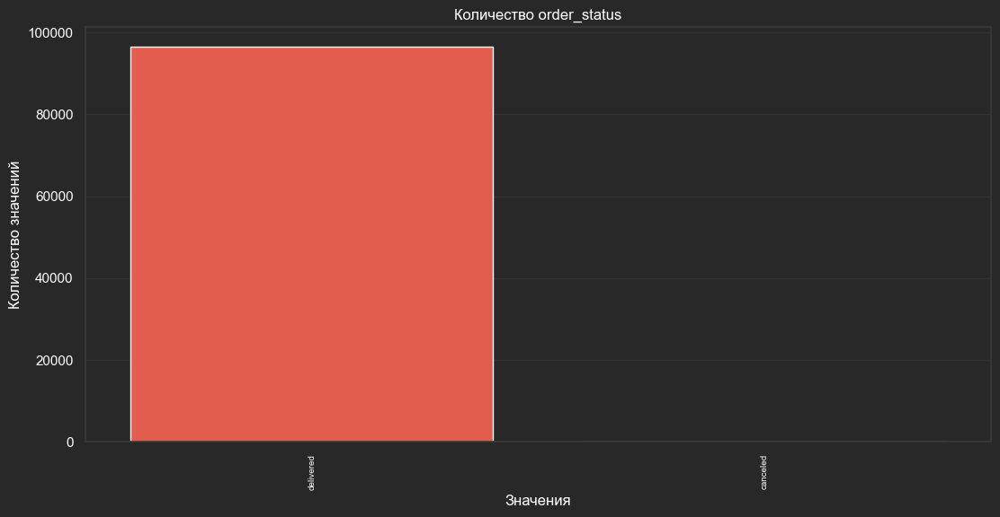

In [41]:
count_plot(olist_orders,['order_status'],figsize=(13,6))

In [42]:
olist_orders['order_status'].value_counts()

order_status
delivered    96455
canceled         6
Name: count, dtype: int64

Большинство заказов были доставлены (96455) и лишь 6 заказов были отменены.

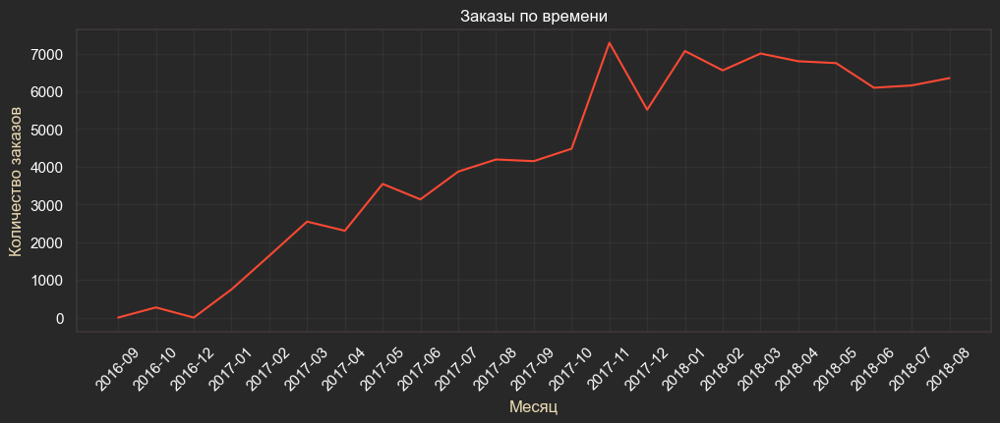

In [43]:
monthly_counts_orders = olist_orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

plt.figure(figsize=(12,4))
sns.lineplot(
    x=monthly_counts_orders.index.astype(str),
    y=monthly_counts_orders.values,
)
plt.xticks(rotation=45)
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.title('Заказы по времени')
plt.show()

Наибольшее количество отзывов приходится на период с 2017-11 по 2018-08 (от 5500 до ~ 7000 отзывов в месяц). С 2016-10 по 2017-01 было минимальное количество отзывов (<200 в месяц). Вероятно, 2018 год вышел пиком продаж, а в 2016 бизнес только развивался. 2017-11 - месяцем с наибольшим объемом заказов (~ 7300)

#### olist_products

* product_id: уникальный идентификатор продукта.
* product_category_head: категория продукта.
* product_name_length: количество символов из названия продукта.
* product_description_length: количество символов из описания продукта.
* product_photos_qty: количество фотографий продукта.
* product_weight_g: вес продукта в граммах.
* product_length_cm: длина изделия ив сантиметрах.
* product height_cm: высота изделия в саинтиметрах.
* product_width_cm: ширина изделия в сантиметрах.

In [44]:
olist_products.head()


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [45]:
olist_products.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [46]:
print(f"Наличие явных дубликатов в датасете 'olist_products': {olist_products.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_products': 0


In [47]:
olist_products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Количество пропусков немного относительно выборки, можно удалить их при этом не потеряв много важной информации.

In [48]:
olist_products.dropna(inplace=True)

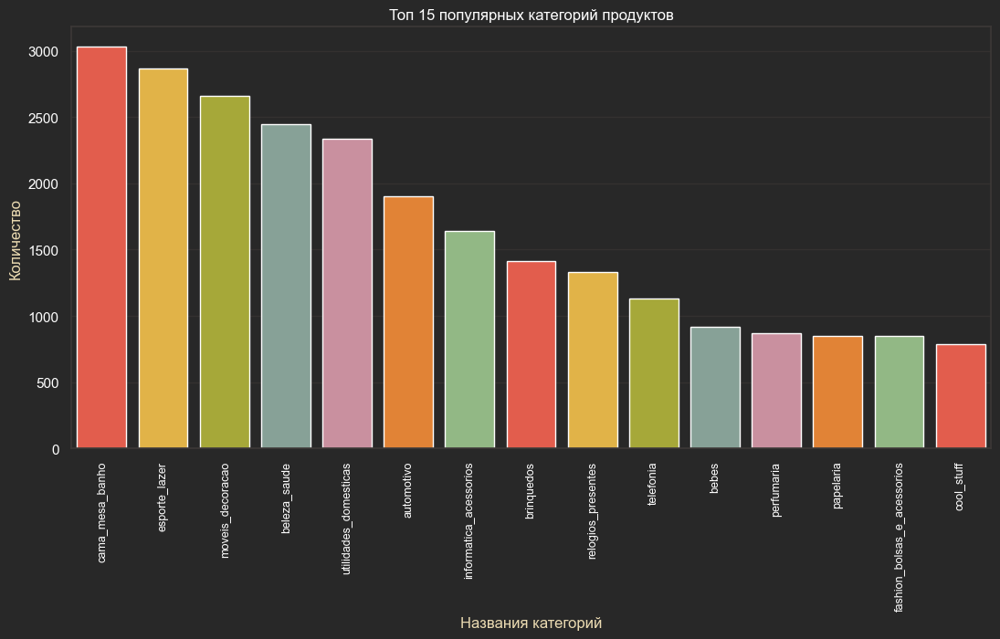

In [49]:
plt.figure(figsize=(13,6))
sns.barplot(olist_products['product_category_name'].value_counts().sort_values(ascending=False).head(15), palette=colorbox)
plt.title('Топ 15 популярных категорий продуктов')
plt.ylabel('Количество')
plt.xlabel('Названия категорий')
plt.xticks(fontsize=9, rotation=90)
plt.show()

In [50]:
print('Топ 10 популярных категорий товаров: \n \n', olist_products['product_category_name'].value_counts()[:10])

Топ 10 популярных категорий товаров: 
 
 product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64


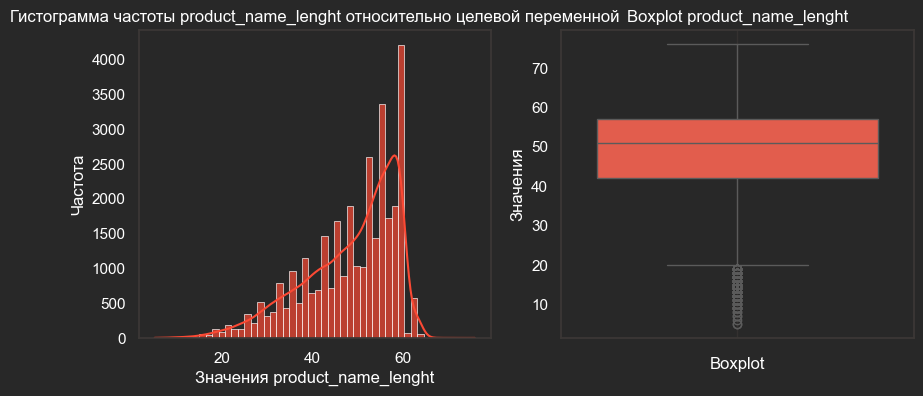

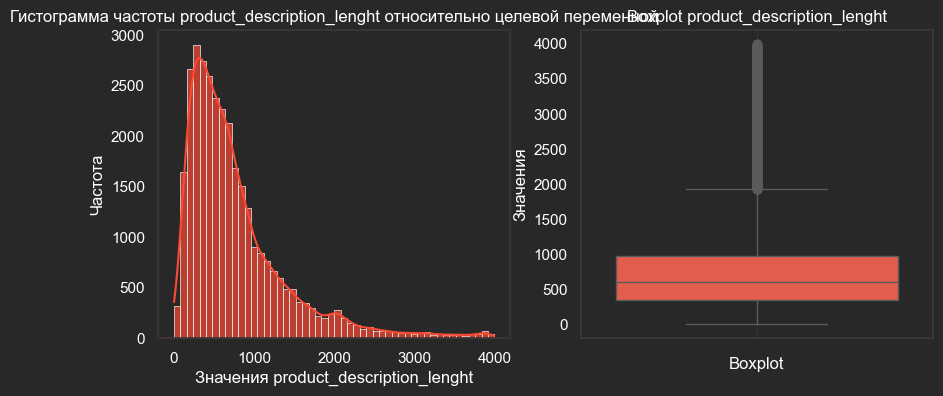

In [51]:
num_plot(olist_products, ['product_name_lenght', 'product_description_lenght'], figsize=(10,4))

In [52]:
print(olist_products['product_name_lenght'].describe(), '\n')
olist_products['product_name_lenght'].describe()

count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64 



count    32340.000000
mean        48.476592
std         10.245699
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64

**product_name_lenght и product_description_lenght**


* product_name_lenght: 

Распределение близко к нормальному - гистограмма симметрична с пиком около 55-60 символов, медиана (51) и среднее (48.5) близки, std умеренное (10.25). IQR от 42 до 57 - разброс небольшой. Боксплот показывает редкие выбросы снизу (минимум 5 символов). Признак не требует трансформаций перед масштабированием.

* product_description_lenght: 

Выраженный правый скос: пик гистограммы в диапазоне 200-500 символов, но среднее (771) заметно выше медианы (595) из-за длинного хвоста. IQR широкий - от 339 до 972. Максимум почти 4 000 символов.

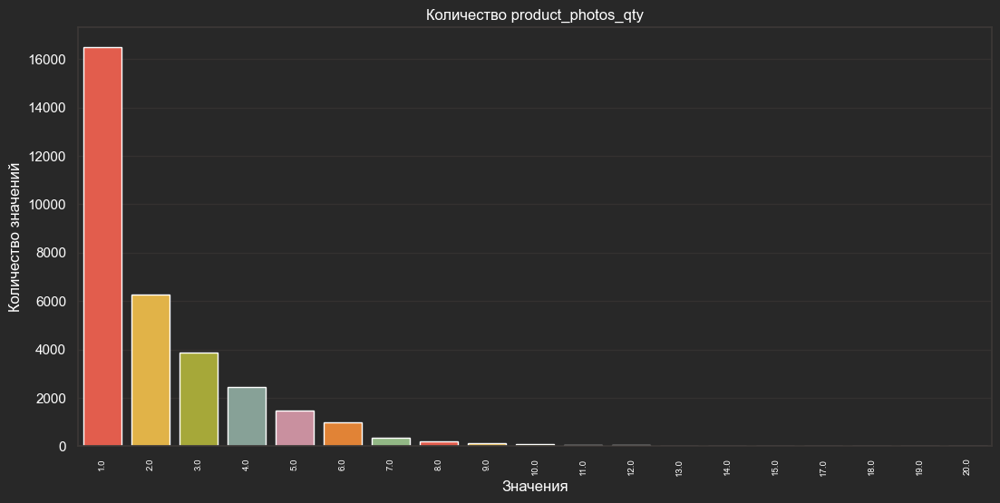

In [53]:
count_plot(olist_products, ['product_photos_qty'], figsize=(13,6))

Большинство продавцов прикладывают минимальное количество фото от 1 до 6. Больше 10 фотографий и до 20 встречаются очень редко

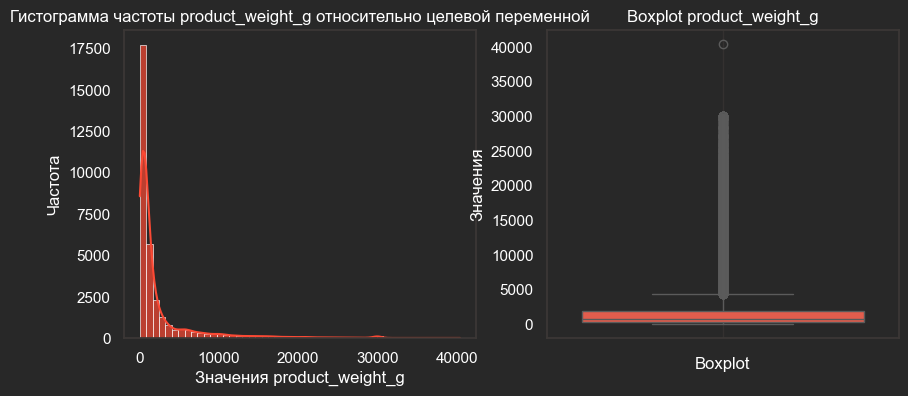

In [54]:
num_plot(olist_products, ['product_weight_g'], figsize=(10,4))

In [55]:
olist_products['product_weight_g'].describe()

count    32340.000000
mean      2276.956586
std       4279.291845
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

Вес товара - один из самых скошенных признаков в датасете. Медиана - 700 г, среднее - 2 276 г, максимум - 40 425 г. Стандартное отклонение (4 282) почти вдвое превышает среднее (дисперсия экстремальная). IQR от 300 до 1 900 г показывает, что 50% товаров.

In [56]:
olist_products.loc[olist_products['product_weight_g'] > 40000]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0


В признаке product_weight_g зафиксирована аномальная запись: товар категории cama_mesa_banho имеет вес 40 425 г при габаритах 13×65×28 см. Такое соотношение веса и размеров физически нереалистично

In [57]:
olist_products = olist_products.loc[olist_products['product_weight_g'] < 40000]

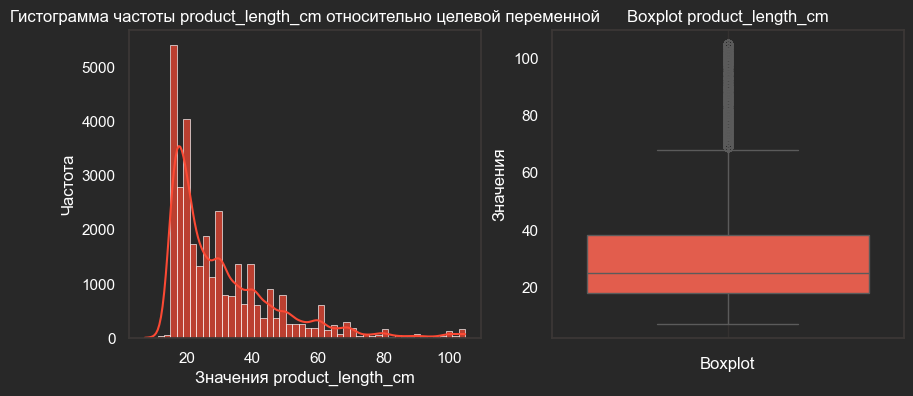

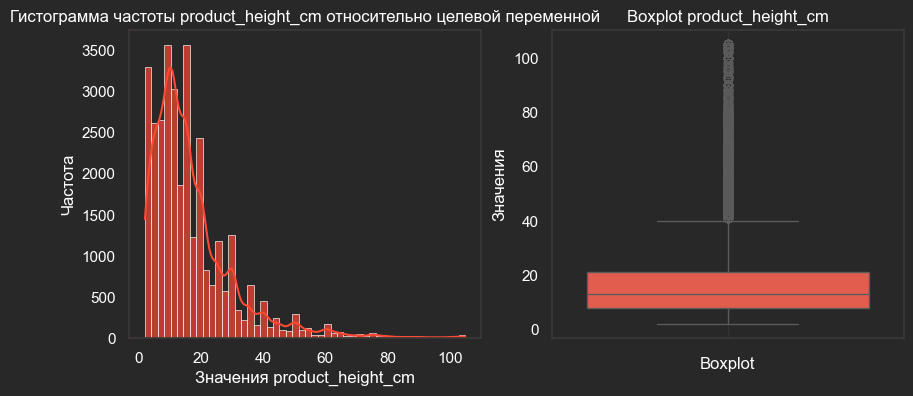

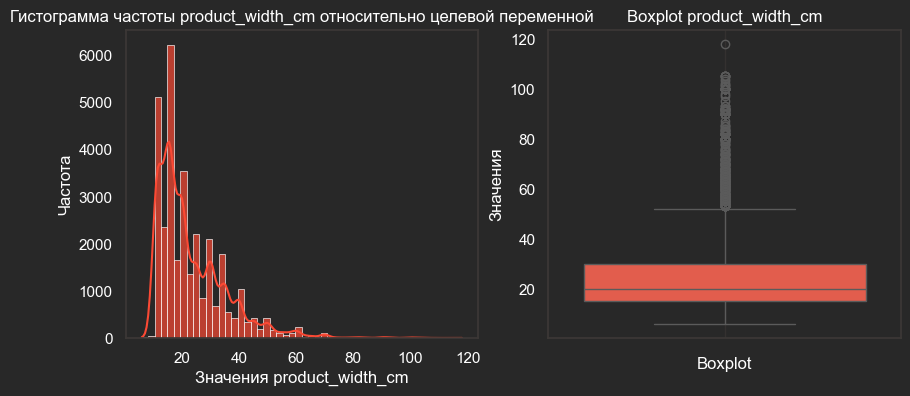

In [58]:
num_plot(olist_products, ['product_length_cm', 'product_height_cm', 'product_width_cm'], figsize=(10,4))

**product_length_cm, product_height_cm, product_width_cm**

Все три размерных признака демонстрируют схожую структуру - правосторонний скос с основной массой значений в нижнем диапазоне и длинным хвостом.

#### olist_sellers

* seller_id - уникальный идентификатор продавца.
* seller_zip_code_prefix - первые пять цифр почтового индекса.
* seller_city - город продавца.
* seller_state - штат продавца.

In [59]:
olist_sellers.head()


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [60]:
olist_sellers.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [61]:
print(f"Наличие явных дубликатов в датасете 'olist_sellers': {olist_sellers.duplicated().sum()}")

Наличие явных дубликатов в датасете 'olist_sellers': 0


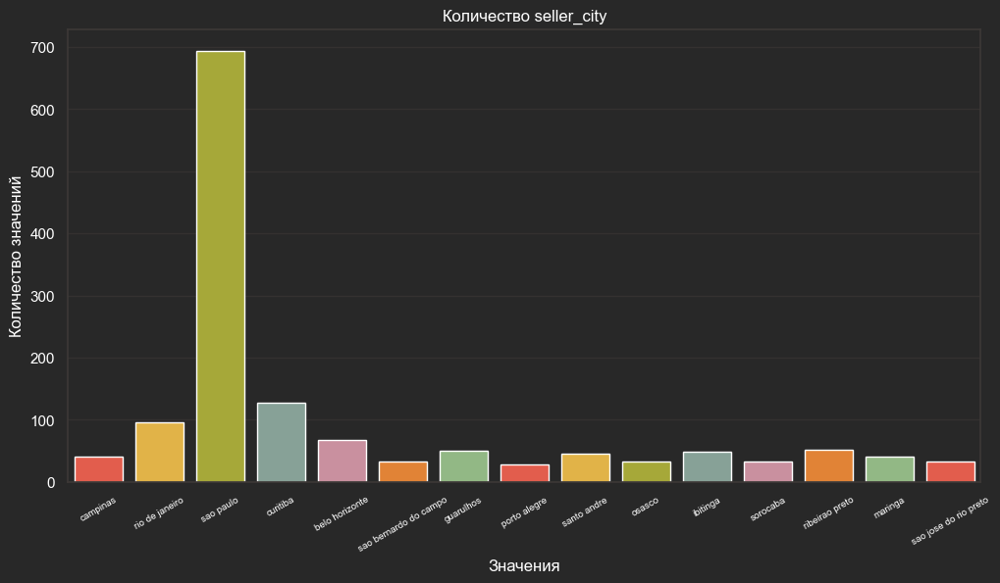

In [62]:
seller_city_names = olist_sellers['seller_city'].value_counts().sort_values(ascending=False).index
seller_city_names = seller_city_names[:15]
the_most_frequent_seller_cities = olist_sellers.loc[olist_sellers['seller_city'].isin(seller_city_names)]
count_plot(the_most_frequent_seller_cities, ['seller_city'], figsize=(12,6), rotation=30)

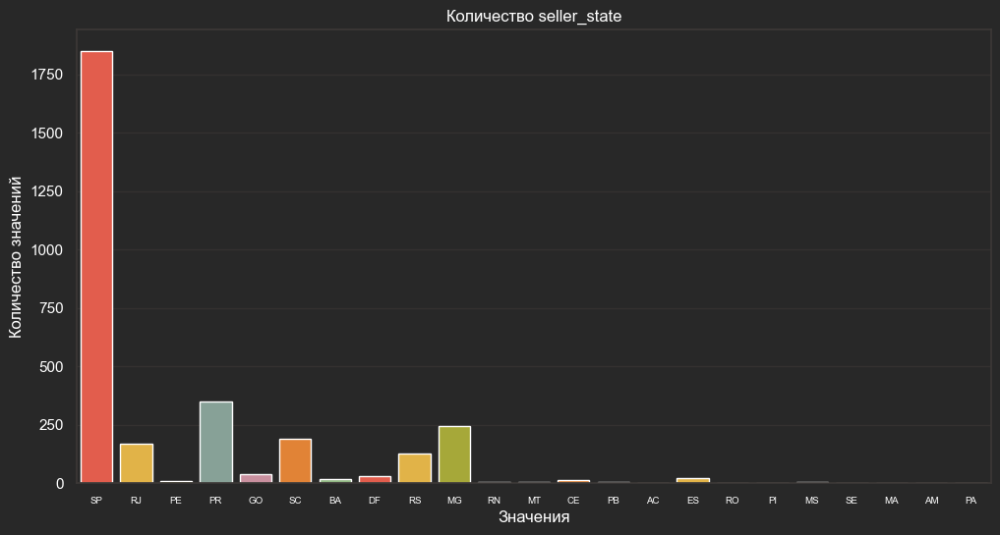

In [63]:
count_plot(olist_sellers, ['seller_state'], figsize=(12,6), rotation=0)

Продавцы сконцентрированы ещё сильнее, чем покупатели. Штат Сан-Паулу (SP) даёт 1 849 продавцов из ~3 095 (почти 60%). Следующие: Парана (PR, 349) и Минас-Жерайс (MG, 244). Многие штаты представлены единицами продавцов (AC, MA, AM, PA по 1). Среди городов лидирует Сан-Паулу (694), далее Куритиба (127) и Рио-де-Жанейро (96).

#### product_cat_name_translation

* product_category_name - название на родном языке
* product_category_name_english - перевод на английский

In [64]:
product_cat_name_translation.head()


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [65]:
product_cat_name_translation.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [66]:
print(f"Наличие явных дубликатов в датасете 'product_cat_name_translation': {product_cat_name_translation.duplicated().sum()}")

Наличие явных дубликатов в датасете 'product_cat_name_translation': 0


# Join таблиц

In [67]:
delivered = olist_orders[olist_orders['order_status'] == 'delivered'].copy()

print("Диапазон дат:\n")
print("min:", delivered['order_purchase_timestamp'].min())
print("max:", delivered['order_purchase_timestamp'].max())

Диапазон дат:

min: 2016-09-15 12:16:38
max: 2018-08-29 15:00:37


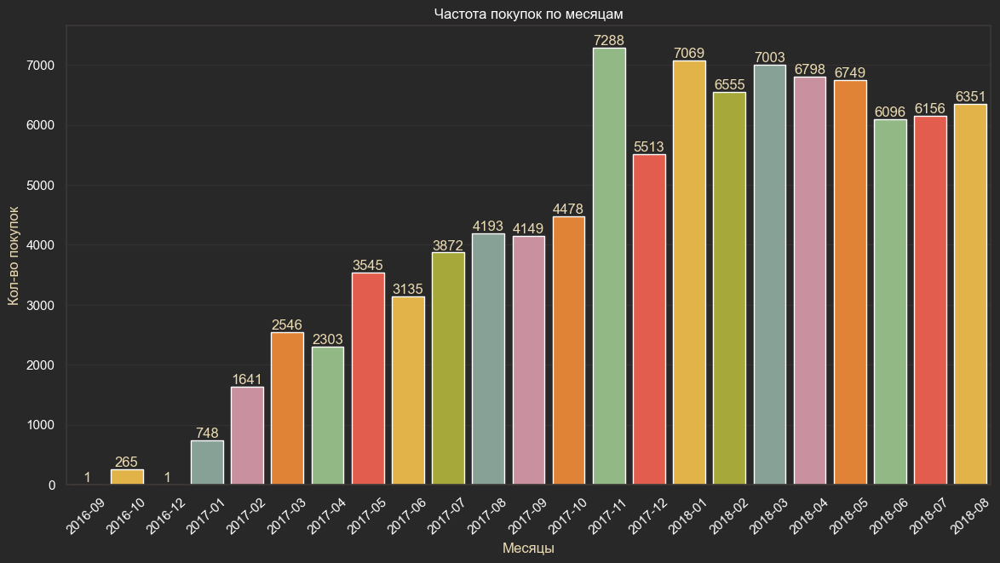

In [68]:
plt.figure(figsize=(14,7))
sns.barplot(delivered.groupby(
    delivered['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].count(), palette=colorbox)

for i, v in enumerate(delivered.groupby(
    delivered['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].count().values):
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=12)

plt.title('Частота покупок по месяцам')
plt.xlabel('Месяцы')
plt.xticks(rotation=42)
plt.ylabel('Кол-во покупок')
plt.show()

По данным продаж за два года можно сделать вывод, что  начиная с 2016-09 по 2017-01 данные являются стартом продаж. Сентябрь и Декабрь 2016 года выдались провальными - одна покупка за месяц. С 2017-11 по конец отчетной даты количество продаж равномерно распределены. В этот период компанией ежемесячно совершается от ~5500 до ~7300 продаж. 

In [69]:
delivered = delivered.merge(olist_customers[['customer_id','customer_unique_id']], on='customer_id', how='left')

In [70]:
delivered['customer_unique_id'].value_counts().reset_index()['count'].value_counts().sort_index()

count
1     90536
2      2572
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [71]:
delivered['customer_unique_id'].value_counts().reset_index()['count'].value_counts(normalize=True).sort_index()

count
1     0.970001
2     0.027556
3     0.001939
4     0.000300
5     0.000096
6     0.000054
7     0.000032
9     0.000011
15    0.000011
Name: proportion, dtype: float64

Основной поведенческий паттерн клиентов - это разовая покупка, которая встречается в 97% случаев. Количество повторных покупок за 2 года составляет менее 3%:

* Вторая покупка в магазине совершается в 2.7% случаев.
    
* Три покупки были сделаны лишь у 0.2% покупателей за весь период времени.
    
* Больее трех покупок наблюдается у менее чем 0.1% покупателей.

In [72]:
delivered = delivered.sort_values('order_purchase_timestamp').reset_index(drop=True)
cutoffs = pd.date_range(start='2017-04-01', end='2018-02-01', freq='MS')
print('Снапшоты:', cutoffs.tolist())

Снапшоты: [Timestamp('2017-04-01 00:00:00'), Timestamp('2017-05-01 00:00:00'), Timestamp('2017-06-01 00:00:00'), Timestamp('2017-07-01 00:00:00'), Timestamp('2017-08-01 00:00:00'), Timestamp('2017-09-01 00:00:00'), Timestamp('2017-10-01 00:00:00'), Timestamp('2017-11-01 00:00:00'), Timestamp('2017-12-01 00:00:00'), Timestamp('2018-01-01 00:00:00'), Timestamp('2018-02-01 00:00:00')]


Отсортировал данные по дате оплаты заказа. Создал список срезов для разметки и агрегации данных.

In [73]:
all_snapshots = []

for cutoff in cutoffs:
    burn_in_start = cutoff - pd.DateOffset(months=BURN_IN_MONTHS)
    horizon_end = cutoff + pd.DateOffset(months=HORIZON_MONTHS)  
    obs = delivered[
        (delivered['order_purchase_timestamp'] >= burn_in_start) &
        (delivered['order_purchase_timestamp'] <  cutoff)
    ].copy()
    obs = obs.merge(
        olist_order_items[['order_id', 'price', 'freight_value']],
        on='order_id', how='inner'
    )
    obs = obs.merge(
        olist_order_payments.groupby('order_id').agg(
            payment_value        = ('payment_value', 'sum'),
            payment_installments = ('payment_installments', 'max'),
            payment_type_credit  = ('payment_type', lambda x: (x == 'credit_card').sum()),
            payment_type_boleto  = ('payment_type', lambda x: (x == 'boleto').sum()),
        ).reset_index(),
        on='order_id', how='inner'
    )
    obs = obs.merge(
        olist_order_reviews[['order_id', 'review_score']],
        on='order_id', how='inner'
    )

    obs['delivery_delay_days'] = (
        obs['order_delivered_customer_date'] - obs['order_estimated_delivery_date']
    ).dt.days
    obs['is_late']       = (obs['delivery_delay_days'] > 0).astype(int)
    obs['hour']          = obs['order_purchase_timestamp'].dt.hour
    obs['dayofweek']     = obs['order_purchase_timestamp'].dt.dayofweek
    obs['is_weekend']    = (obs['dayofweek'] >= 5).astype(int)
    obs['is_night']      = ((obs['hour'] >= 22) | (obs['hour'] <= 6)).astype(int)
    obs['freight_ratio'] = obs['freight_value'] / (obs['price'] + 1)

    customers_before = obs[['customer_unique_id']].drop_duplicates()

    customers_after = (
        delivered[
            (delivered['order_purchase_timestamp'] >= cutoff) &
            (delivered['order_purchase_timestamp'] <  horizon_end)
        ][['customer_unique_id']].drop_duplicates()
        .assign(bought_after=1)
    )

    target_snap = customers_before.merge(
        customers_after, on='customer_unique_id', how='left'
    )
    target_snap['churn'] = target_snap['bought_after'].isna().astype(int)
    target_snap = target_snap[['customer_unique_id', 'churn']]

    #Агреграция
    features = obs.groupby('customer_unique_id').agg(
        num_orders        = ('order_id','nunique'),
        num_items         = ('price','count'),
        total_spent       = ('price','sum'),
        avg_order_price   = ('price','mean'),
        max_order_price   = ('price','max'),
        last_order_price  = ('price','last'),
        total_freight     = ('freight_value','sum'),
        avg_payment_value = ('payment_value','mean'),
        avg_installments  = ('payment_installments','mean'),
        first_order_date  = ('order_purchase_timestamp','min'),
        last_order_date   = ('order_purchase_timestamp','max'),
        avg_review_score  = ('review_score','mean'),
        min_review_score  = ('review_score','min'),
        last_review_score = ('review_score','last'),
        num_bad_reviews   = ('review_score', lambda x: (x <= 2).sum()),
        num_good_reviews  = ('review_score', lambda x: (x >= 4).sum()),
        num_late_deliveries = ('is_late','sum'),
        avg_delay_days    = ('delivery_delay_days','mean'),
        num_credit_payments = ('payment_type_credit','sum'),
        num_boleto_payments = ('payment_type_boleto','sum'),
        avg_purchase_hour = ('hour','mean'),
        pct_weekend_orders = ('is_weekend','mean'),
        pct_night_orders  = ('is_night','mean'),
        avg_freight_ratio = ('freight_ratio','mean'),
        max_freight_ratio = ('freight_ratio','max'),
    ).reset_index()

    #Временные признаки
    features['customer_tenure_days']  = (cutoff - features['first_order_date']).dt.days
    features['days_since_last_order'] = (cutoff - features['last_order_date']).dt.days
    features['avg_days_between_orders'] = np.where(
        features['num_orders'] > 1,
        features['customer_tenure_days'] / (features['num_orders'] - 1),
        features['customer_tenure_days']
    )
    features['late_delivery_rate'] = (
        features['num_late_deliveries'] / features['num_orders']
    )
    features = features.drop(columns=['first_order_date', 'last_order_date'])
    features['snapshot_date']  = cutoff
    features['snapshot_month'] = cutoff.month  # для сезонности как фича

    #Снапшот
    snap = features.merge(target_snap, on='customer_unique_id', how='inner')
    print(f'Кол-во строк: {snap.shape[0]}, соотношение классов: {snap["churn"].mean():.3f}')
    all_snapshots.append(snap)

Кол-во строк: 4797, соотношение классов: 0.984
Кол-во строк: 6339, соотношение классов: 0.984
Кол-во строк: 8168, соотношение классов: 0.982
Кол-во строк: 8729, соотношение классов: 0.981
Кол-во строк: 10228, соотношение классов: 0.982
Кол-во строк: 10862, соотношение классов: 0.981
Кол-во строк: 11843, соотношение классов: 0.981
Кол-во строк: 12444, соотношение классов: 0.983
Кол-во строк: 15479, соотношение классов: 0.984
Кол-во строк: 16831, соотношение классов: 0.986
Кол-во строк: 19368, соотношение классов: 0.986


In [74]:
df_model = pd.concat(all_snapshots, ignore_index=True)

print('Финальный датасет')
print(f'Размерность: {df_model.shape}')
print(f'\nБаланс классов:')
print(df_model['churn'].value_counts())
print(df_model['churn'].value_counts(normalize=True).round(3))
print(f'\nПропуски:')
print(df_model.isnull().sum().sort_values(ascending=False).head(10))
print(f'\nКоличество дубликатов: {df_model.duplicated().sum()}')

Финальный датасет
Размерность: (125088, 31)

Баланс классов:
churn
1    123036
0      2052
Name: count, dtype: int64
churn
1    0.984
0    0.016
Name: proportion, dtype: float64

Пропуски:
customer_unique_id         0
avg_delay_days             0
snapshot_month             0
snapshot_date              0
late_delivery_rate         0
avg_days_between_orders    0
days_since_last_order      0
customer_tenure_days       0
max_freight_ratio          0
avg_freight_ratio          0
dtype: int64

Количество дубликатов: 0


Дисбаланс классов ~98% | ~2%, пропуски и дубликаты отсутствуют

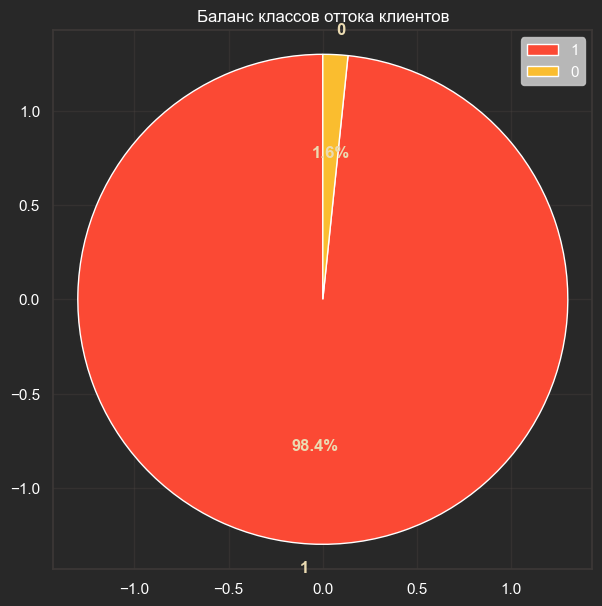

In [75]:
pie_charm(df_model['churn'], title='Баланс классов оттока клиентов')

Сильнейший дисбаланс классов: 98% клиентов за все время не совершали повторных покупок в течении горизонта, что может свидетельствовать о том, что магазин пользуется спросом для разовых покупок дорогих и долгосрочных вещей, например: электротехники, мебели и других товаров. Покупатель нескоро возвращается за повторными покупками. Для работы с дисбалансом классов планирую использовать class_weight

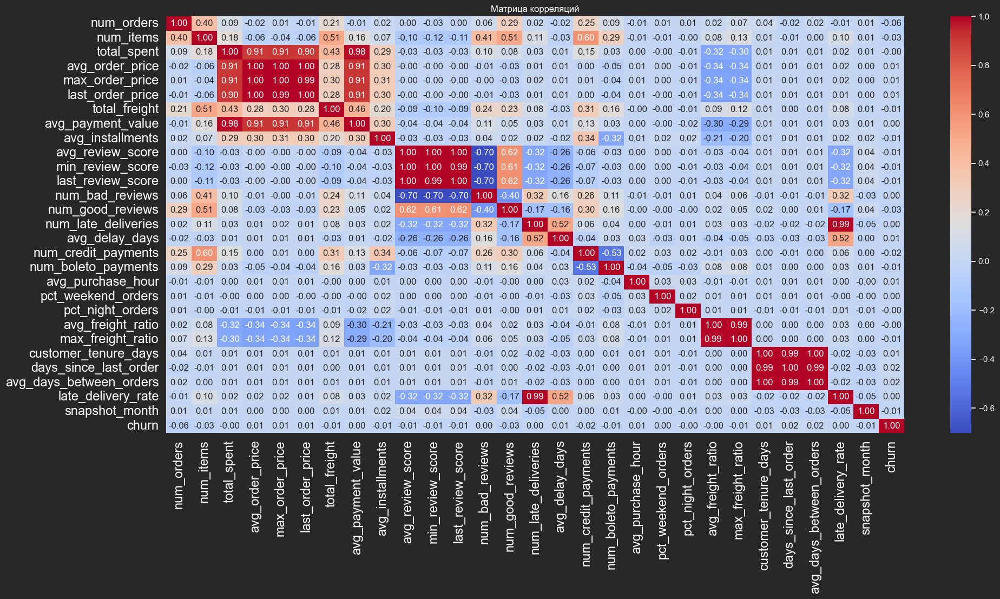

In [76]:
plt.figure(figsize=(22,10))
corr_with_target = df_model.drop(['customer_unique_id','snapshot_date'], axis=1).corr()
sns.heatmap(corr_with_target, annot=True, fmt='.2f', cbar=True, cmap='coolwarm')
plt.title('Матрица корреляций')
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.show()

Мультиколлинеарность которую удалось выявить в следующих признаках:

* total_spent,
* avg_order_price,
* max_order_price,
* last_order_price,
* avg_payment_value

Они все коррелируют между собой на уровне 0.90-1.00. Это фактически один и тот же сигнал в пяти колонках. Для дерева это не критично, но логрегрессия чувствительна к мультиколлинеарности, придется оставить только один признак из пяти.

-----------------------------------------------------------------------------------------------------------------------
* customer_tenure_days,
* days_since_last_order,
* avg_days_between_orders

Признаки имеют высокую корреляцию (0.99). Три признака несут почти идентичную информацию, необходимо также выбрать один наиболее информативный и интерпретируемый.

-----------------------------------------------------------------------------------------------------------------------
* avg_freight_ratio и max_freight_ratio; num_late_deliveries и late_delivery_rate, а также avg_review_score, min_review_score и last_review_score (0.98-1.00) - аналогично, оставляем один из пар.
-----------------------------------------------------------------------------------------------------------------------
*  num_credit_payments и num_boleto_payments - -0.53, умеренная обратная связь, оба можно оставить.


Все корреляции с churn близки к нулю (максимум -0.06). Линейные связи отстутствуют.

# Обучение модели

In [77]:
train = df_model[df_model['snapshot_date'] <=  pd.Timestamp('2017-10-01')]
val   = df_model[df_model['snapshot_date'] == pd.Timestamp('2017-11-01')]
test  = df_model[df_model['snapshot_date'] >= pd.Timestamp('2017-12-01')]

X_train = train.drop(columns=['customer_unique_id', 'churn', 'snapshot_date'])
y_train = train['churn']
X_val   = val.drop(columns=['customer_unique_id', 'churn', 'snapshot_date'])
y_val   = val['churn']
X_test  = test.drop(columns=['customer_unique_id', 'churn', 'snapshot_date'])
y_test  = test['churn']
print(f'Train: {X_train.shape} | churn: {y_train.mean():.3f}')
print(f'Val:   {X_val.shape}   | churn: {y_val.mean():.3f}')
print(f'Test:  {X_test.shape}  | churn: {y_test.mean():.3f}')

# Для линейки
X_train_lr = train.drop(columns=[
    'customer_unique_id',
    'churn',
    'snapshot_date',
    'max_order_price',
    'last_order_price',
    'avg_payment_value',
    'customer_tenure_days',
    'days_since_last_order',
    'max_freight_ratio',
    'num_late_deliveries',
    'late_delivery_rate',
    'min_review_score', 
    'last_review_score'
])
y_train = train['churn']
X_val_lr   = val.drop(columns=[
    'customer_unique_id',
    'churn',
    'snapshot_date',
    'max_order_price',
    'last_order_price',
    'avg_payment_value',
    'customer_tenure_days',
    'days_since_last_order',
    'max_freight_ratio',
    'num_late_deliveries',
    'late_delivery_rate',
    'min_review_score', 
    'last_review_score'
])
y_val   = val['churn']
X_test_lr  = test.drop(columns=[
    'customer_unique_id',
    'churn',
    'snapshot_date',
    'max_order_price',
    'last_order_price',
    'avg_payment_value',
    'customer_tenure_days',
    'days_since_last_order',
    'max_freight_ratio',
    'num_late_deliveries',
    'late_delivery_rate',
    'min_review_score', 
    'last_review_score'
])
y_test  = test['churn']
print(f'Train logreg: {X_train.shape} | churn: {y_train.mean():.3f}')
print(f'Val logreg:   {X_val.shape}   | churn: {y_val.mean():.3f}')
print(f'Test logreg:  {X_test.shape}  | churn: {y_test.mean():.3f}')

Train: (60966, 28) | churn: 0.982
Val:   (12444, 28)   | churn: 0.983
Test:  (51678, 28)  | churn: 0.986
Train logreg: (60966, 28) | churn: 0.982
Val logreg:   (12444, 28)   | churn: 0.983
Test logreg:  (51678, 28)  | churn: 0.986


Разбил данные на обучающую, валидационную и тестовую выборки с фильтрацией по времени

In [78]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_val = sc.transform(X_val)
X_test = sc.transform(X_test)
#logreg
X_train_lr = sc.fit_transform(X_train)
X_val_lr = sc.transform(X_val)
X_test_lr = sc.transform(X_test)

Отмасштабировал числовые признаки

#### Baseline logreg

Лишние столбца и признаки с мультиколлинеарностью были удалены, признаки масштабированы 

In [79]:
lr = LogisticRegression(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    max_iter=1000
)
lr.fit(X_train_lr, y_train)
y_pred_lr = lr.predict(X_val_lr)
y_proba_lr = lr.predict_proba(X_val)[:, 1]
print("Метрики на валидационных данных:")
model_metrics(y_val,y_pred_lr, y_proba_lr)

Метрики на валидационных данных:
ROC-AUC : 0.5830
PR-AUC  : 0.9866
Gini    : 0.1660
Lift@10 : 1.0063
Lift@20 : 1.0059
Recall  : 0.5065


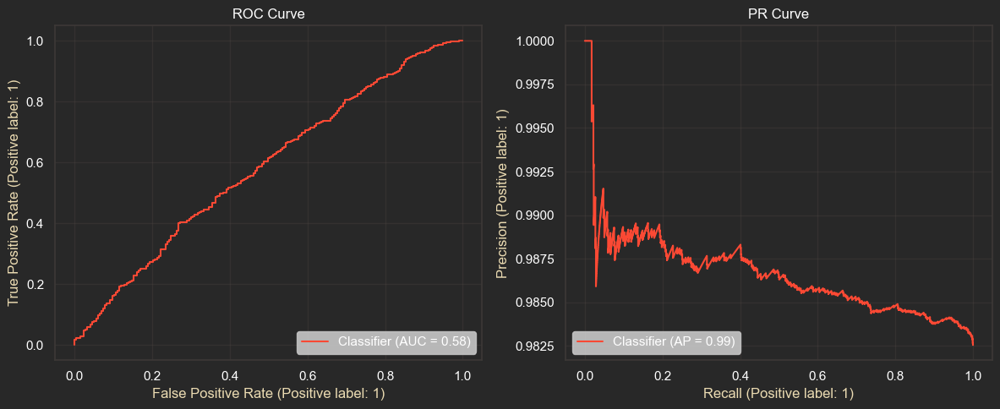

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_lr, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_lr, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [81]:
threshold_report(y_val, y_proba_lr)

Threshold  F1         Recall     Precision 
0.50      0.669     0.507     0.986     
0.40      0.954     0.925     0.984     
0.30      0.985     0.986     0.983     
0.20      0.988     0.993     0.983     
0.10      0.991     0.998     0.983     


Линейная модель плохо справляется с задачей оттока: низкий roc-auc (0.58) является достаточно случайным разделением классов, recall = 0.50 - модель нашла только 50% всех положительных классов, модель не смогла выявить значимые и линейные закономерности.

#### RandomForestClassifier

In [82]:
param_rfc = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5],
    'max_features': ['sqrt', 'log2'],
}

rs_rfc = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
    param_rfc,
    n_iter=20,
    cv=3,
    n_jobs=-1,
    scoring='average_precision',
    random_state=RANDOM_STATE,
    verbose=1
)
rs_rfc.fit(X_train,y_train)

best_rs_rfc = rs_rfc.best_estimator_
best_params_rs_fct = rs_rfc.best_params_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [83]:
print(f'Наилучшая модель: {best_rs_rfc}, наилучший результат модели: {rs_rfc.best_score_}\n')
print("Метрики на валидационных данных:")
y_pred_rfc = best_rs_rfc.predict(X_val)
y_proba_rfc = best_rs_rfc.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_rfc, y_proba_rfc)

Наилучшая модель: RandomForestClassifier(class_weight='balanced', max_features='log2',
                       min_samples_split=10, random_state=42), наилучший результат модели: 0.9911436626020497

Метрики на валидационных данных:
ROC-AUC : 0.8246
PR-AUC  : 0.9948
Gini    : 0.6492
Lift@10 : 1.0145
Lift@20 : 1.0141
Recall  : 1.0000


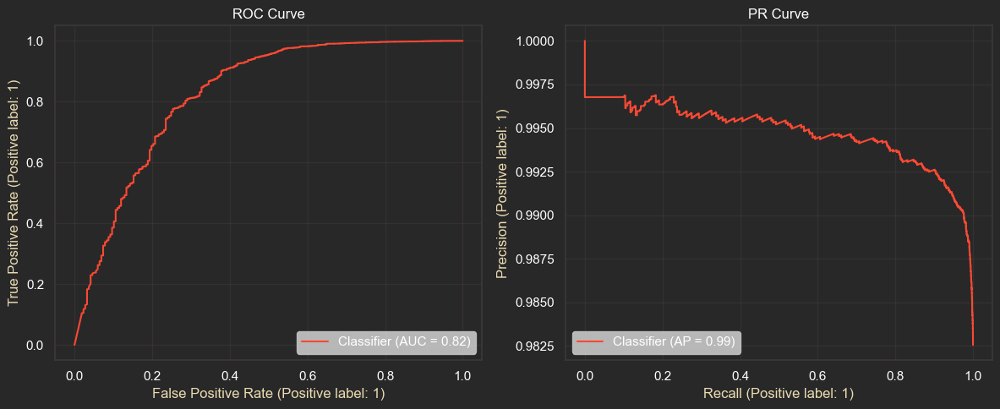

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_rfc, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_rfc, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [85]:
threshold_report(y_val, y_proba_rfc)

Threshold  F1         Recall     Precision 
0.50      0.991     1.000     0.983     
0.40      0.991     1.000     0.983     
0.30      0.991     1.000     0.983     
0.20      0.991     1.000     0.983     
0.10      0.991     1.000     0.983     


ROC-AUC сильно лучше чем у логистической регрессии (0.825 > 0.58), но можно заметить, что recall = 1 при всех порогах, что может быть возможно только если модель предсказывает всех клиентов как ушедших.

#### lightGBM

In [86]:
param_lgb = {
    'n_estimators':    [200, 500],
    'max_depth':       [4, 6, 8],
    'learning_rate':   [0.01, 0.05, 0.1],
    'num_leaves':      [15, 31, 63],
    'min_child_samples': [10, 20, 50],
    'subsample':       [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9],
}

rs_lgb = RandomizedSearchCV(
        LGBMClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced',
        is_unbalance=True,
        verbose=-1
    ),
    param_lgb,
    n_iter=20,
    cv=3,
    scoring='average_precision',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
rs_lgb.fit(X_train, y_train)
best_lgb = rs_lgb.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [87]:
print(f'Наилучшая модель: {best_lgb}, наилучший результат модели: {rs_lgb.best_score_}\n')
print("Метрики на валидационных данных:")
y_pred_lgb = best_lgb.predict(X_val)
y_proba_lgb = best_lgb.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_lgb, y_proba_lgb)

Наилучшая модель: LGBMClassifier(class_weight='balanced', colsample_bytree=0.9, is_unbalance=True,
               max_depth=8, n_estimators=500, num_leaves=63, random_state=42,
               subsample=0.9, verbose=-1), наилучший результат модели: 0.9905402587204392

Метрики на валидационных данных:
ROC-AUC : 0.8122
PR-AUC  : 0.9935
Gini    : 0.6244
Lift@10 : 1.0137
Lift@20 : 1.0124
Recall  : 0.9856


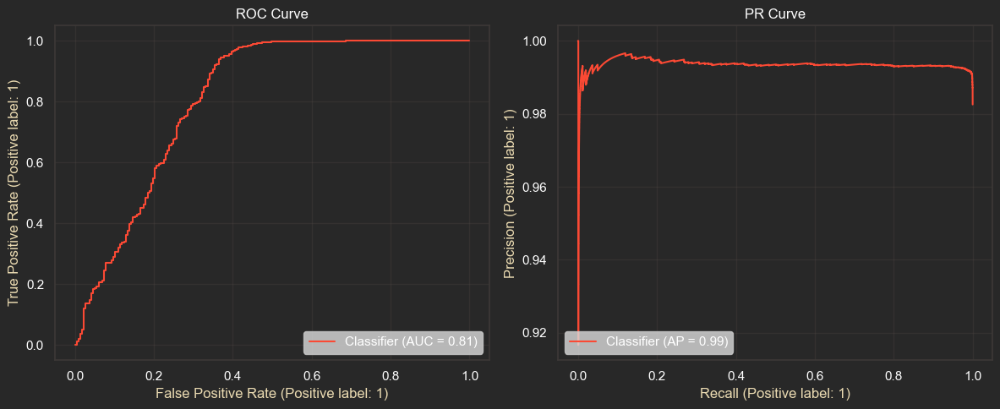

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_lgb, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_lgb, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [89]:
threshold_report(y_val, y_proba_lgb)

Threshold  F1         Recall     Precision 
0.50      0.989     0.986     0.992     
0.40      0.991     0.989     0.992     
0.30      0.992     0.993     0.992     
0.20      0.993     0.995     0.991     
0.10      0.994     0.998     0.991     


ROC-AUC (0.812), PR-AUC(0.994).  При снижении порога до 0.10 Recall растёт до 0.998 при F1=0.994, Precision = 0.991

#### XGBoost

In [90]:
param_xgb = {
    'n_estimators':    [200, 500],
    'max_depth':       [3, 5, 7],
    'learning_rate':   [0.01, 0.05, 0.1],
    'subsample':       [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9],
    'min_child_weight': [1, 5, 10],
}

rs_xgb = RandomizedSearchCV(
        XGBClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced',
        eval_metric='aucpr',
        is_unbalance=True,
        verbosity=0
    ),
    param_xgb,
    n_iter=20,
    cv=3,
    scoring='average_precision',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
rs_xgb.fit(X_train, y_train)
best_xgb = rs_xgb.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [91]:
print(f'Наилучшая модель: {best_xgb}, наилучший результат модели: {rs_xgb.best_score_}\n')
print("Метрики на валидационных данных:")
y_pred_xgb = best_xgb.predict(X_val)
y_proba_xgb = best_xgb.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_xgb, y_proba_xgb)

Наилучшая модель: XGBClassifier(base_score=None, booster=None, callbacks=None,
              class_weight='balanced', colsample_bylevel=None,
              colsample_bynode=None, colsample_bytree=0.9, device=None,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric='aucpr', feature_types=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, is_unbalance=True,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, ...), наилучший результат модели: 0.9907643125137796

Метрики на валидационных данных:
ROC-AUC : 0.8334
PR-AUC  : 0.9949
Gini    : 0.6667
Lift@10 : 1.0137
Lift@20 : 1.0137
Recall  : 0.9998


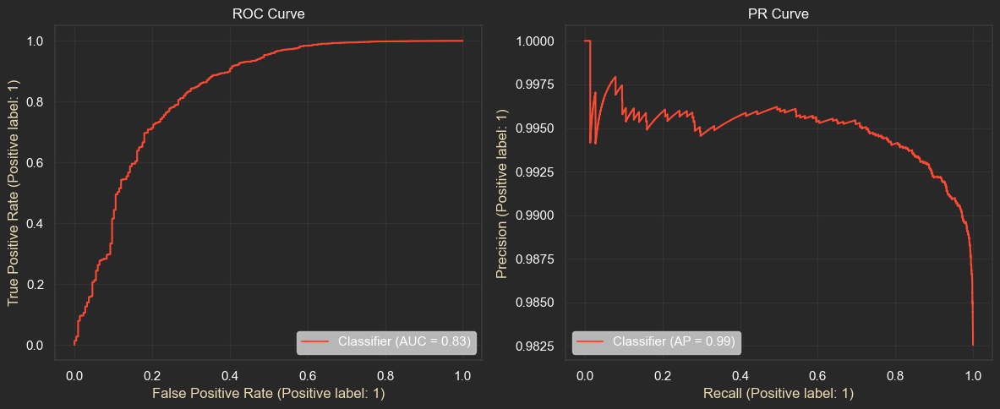

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_xgb, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_xgb, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [93]:
threshold_report(y_val, y_proba_xgb)

Threshold  F1         Recall     Precision 
0.50      0.991     1.000     0.983     
0.40      0.991     1.000     0.983     
0.30      0.991     1.000     0.983     
0.20      0.991     1.000     0.983     
0.10      0.991     1.000     0.983     


Лучший ROC-AUC среди всех моделей (0.58). При этом Recall=1.000 при любом пороге 
от 0.10 до 0.50 - модель предсказывает почти всё как churn=1

#### CatBoost

In [94]:
param_cat = {
    'iterations':      [200, 500],
    'depth':           [4, 6, 8],
    'learning_rate':   [0.01, 0.05, 0.1],
    'l2_leaf_reg':     [1, 3, 5],
}

rs_cat = RandomizedSearchCV(
    CatBoostClassifier(
        random_state=RANDOM_STATE,
        auto_class_weights='Balanced',
        verbose=0
    ),
    param_cat,
    n_iter=20,
    cv=3,
    scoring='average_precision',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
rs_cat.fit(X_train, y_train)
best_cat = rs_cat.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [95]:
print('Лучшие параметры:', rs_cat.best_params_)
print('Лучший CV score:', rs_cat.best_score_)
print("Метрики на валидационных данных:")
y_pred_cat = best_cat.predict(X_val)
y_proba_cat = best_cat.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_cat, y_proba_cat)

Лучшие параметры: {'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 500, 'depth': 8}
Лучший CV score: 0.9912213711131086
Метрики на валидационных данных:
ROC-AUC : 0.8131
PR-AUC  : 0.9944
Gini    : 0.6261
Lift@10 : 1.0137
Lift@20 : 1.0137
Recall  : 0.9747


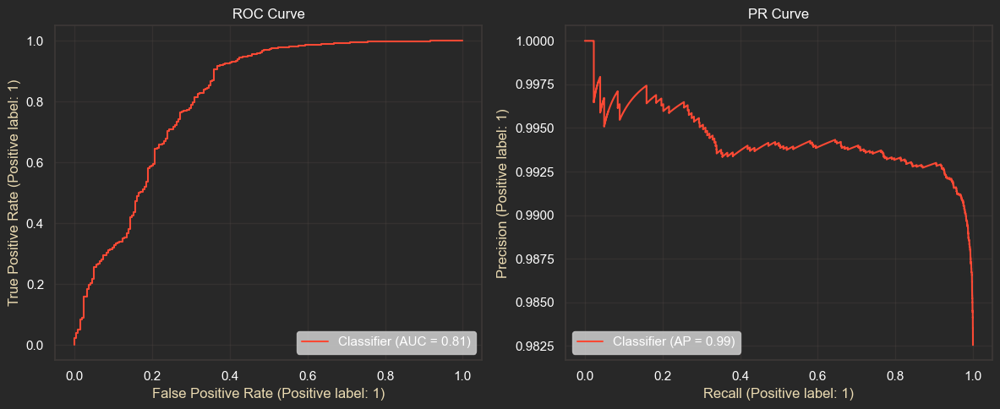

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_cat, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_cat, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [97]:
threshold_report(y_val, y_proba_cat)

Threshold  F1         Recall     Precision 
0.50      0.983     0.975     0.991     
0.40      0.989     0.989     0.989     
0.30      0.991     0.996     0.987     
0.20      0.992     0.999     0.984     
0.10      0.991     1.000     0.983     


Поведение у CatBoost чуть лучше, чем у LightGBM. ROC-AUC = 0.813, PR-AUC = O.994, Recall = 0.975. При спуске по порогам threshold = 0.20 позволяет добиться высокой точности: Recall = 0.999, Precision = 0.984 при F1 = 0.992

# Дообучаем модели

#### LightGBM v2

In [98]:
param_lgb_v2 = {
    'n_estimators':      [500, 1000, 1500],
    'max_depth':         [6, 8, 10],
    'learning_rate':     [0.01, 0.03, 0.05],
    'num_leaves':        [31, 63, 127],
    'min_child_samples': [10, 20, 50],
    'subsample':         [0.7, 0.8, 0.9],
    'colsample_bytree':  [0.7, 0.8, 0.9],
    'reg_alpha':         [0, 0.1, 0.5],
    'reg_lambda':        [1, 3, 5],
}

rs_lgb_v2 = RandomizedSearchCV(
    LGBMClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced',
        verbose=-1
    ),
    param_lgb_v2,
    n_iter=40,
    cv=3,
    scoring='average_precision',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
rs_lgb_v2.fit(X_train, y_train)
best_lgb_v2 = rs_lgb_v2.best_estimator_
print('Лучшие параметры:', rs_lgb_v2.best_params_)
print('Лучший CV score:', rs_lgb_v2.best_score_)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Лучшие параметры: {'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha': 0.1, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Лучший CV score: 0.991246845579913


In [99]:
print("Метрики на валидационных данных:")
y_pred_lgb_v2 = best_lgb_v2.predict(X_val)
y_proba_lgb_v2 = best_lgb_v2.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_lgb_v2, y_proba_lgb_v2)

Метрики на валидационных данных:
ROC-AUC : 0.8088
PR-AUC  : 0.9935
Gini    : 0.6175
Lift@10 : 1.0120
Lift@20 : 1.0132
Recall  : 0.9762


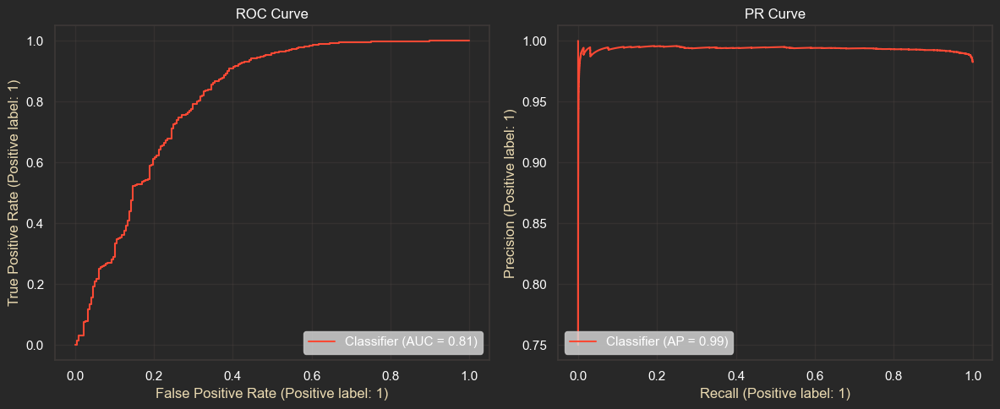

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_lgb_v2, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_lgb_v2, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [101]:
threshold_report(y_val, y_proba_lgb_v2)

Threshold  F1         Recall     Precision 
0.50      0.983     0.976     0.990     
0.40      0.989     0.988     0.989     
0.30      0.991     0.995     0.987     
0.20      0.992     0.999     0.985     
0.10      0.991     1.000     0.983     


#### CatBoost v2

In [102]:
param_cat_v2 = {
    'iterations':    [500, 1000, 1500],
    'depth':         [5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05],
    'l2_leaf_reg':   [1, 3, 5, 10],
    'bagging_temperature': [0, 0.5, 1.0],
    'random_strength': [1, 2, 5],
}

rs_cat_v2 = RandomizedSearchCV(
    CatBoostClassifier(
        random_state=RANDOM_STATE,
        auto_class_weights='Balanced',
        early_stopping_rounds=50,
        eval_metric='AUC',
        verbose=0
    ),
    param_cat_v2,
    n_iter=30,
    cv=3,
    scoring='average_precision',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

rs_cat_v2.fit(X_train, y_train,)
best_cat_v2 = rs_cat_v2.best_estimator_
print('Лучшие параметры:', rs_cat_v2.best_params_)
print('Лучший CV score:', rs_cat_v2.best_score_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Лучшие параметры: {'random_strength': 5, 'learning_rate': 0.05, 'l2_leaf_reg': 3, 'iterations': 1500, 'depth': 8, 'bagging_temperature': 0.5}
Лучший CV score: 0.9913304321805615


In [103]:
print("Метрики на валидационных данных:")
y_pred_cat_v2 = best_cat_v2.predict(X_val)
y_proba_cat_v2 = best_cat_v2.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_cat_v2, y_proba_cat_v2)

Метрики на валидационных данных:
ROC-AUC : 0.8264
PR-AUC  : 0.9946
Gini    : 0.6527
Lift@10 : 1.0153
Lift@20 : 1.0120
Recall  : 0.9950


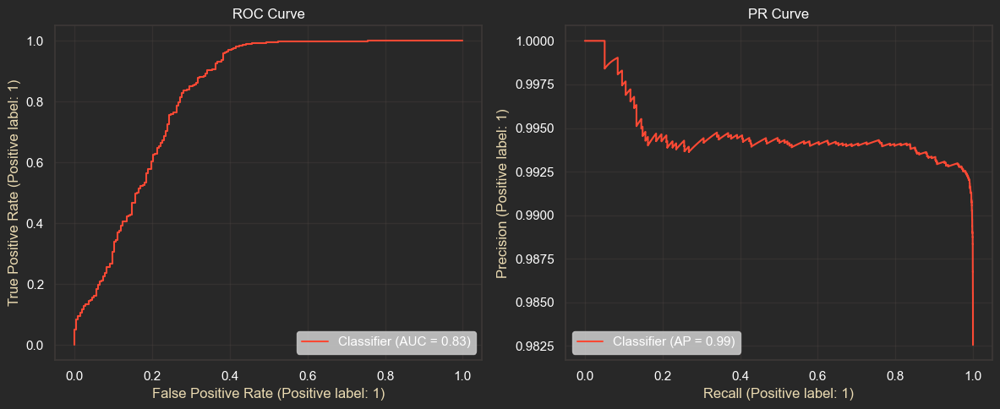

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_cat_v2, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_cat_v2, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [105]:
threshold_report(y_val, y_proba_cat_v2)

Threshold  F1         Recall     Precision 
0.50      0.993     0.995     0.991     
0.40      0.994     0.997     0.991     
0.30      0.994     0.998     0.989     
0.20      0.994     0.999     0.988     
0.10      0.993     1.000     0.986     


PR, ROC и Recall метрики выросли по сравнению с первой CatBoost моделью(ROC-AUC: 0.81 -> 0.826; PR-AUC: 0.99 -> 0.995; Recall: 0.975 -> 0.995). Модель Catboost показала себя лучше lightgbm, поэтому я выбрал ее как конечную модель.

#### CatBoost v3

In [3]:
def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations',500,3000),
        'depth': trial.suggest_int('depth',3,10),
        'learning_rate': trial.suggest_float('learning_rate',0.05,1.0),
        'l2_leaf_reg':         trial.suggest_float('l2_leaf_reg', 1, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0, 1),
        'random_strength':     trial.suggest_float('random_strength', 1, 10)
    }

    model = CatBoostClassifier(
        **params,
        random_state=RANDOM_STATE,
        auto_class_weights='Balanced',
        verbose=0
    )
    model.fit(X_train, y_train)
    
    score = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    return score


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

NameError: name 'optuna' is not defined

In [107]:
best_params_cat_v3 = study.best_params
print('Лучшие параметры:', study.best_params)
print('Лучший CV score:', study.best_value)

Лучшие параметры: {'iterations': 1087, 'depth': 9, 'learning_rate': 0.33314026647733064, 'l2_leaf_reg': 6.57225055839, 'bagging_temperature': 0.49124787433183636, 'random_strength': 5.570242765840525}
Лучший CV score: 0.8350651029545174


In [108]:
print("Метрики на валидационных данных:")
best_cat_v3 = CatBoostClassifier(
    **best_params_cat_v3,
    random_state=RANDOM_STATE,
    auto_class_weights='Balanced',
    verbose=0
)
best_cat_v3.fit(X_train,y_train)
y_pred_cat_v3 = best_cat_v3.predict(X_val)
y_proba_cat_v3 = best_cat_v3.predict_proba(X_val)[:, 1]
model_metrics(y_val,y_pred_cat_v3, y_proba_cat_v3)

Метрики на валидационных данных:
ROC-AUC : 0.8351
PR-AUC  : 0.9946
Gini    : 0.6701
Lift@10 : 1.0120
Lift@20 : 1.0120
Recall  : 0.9956


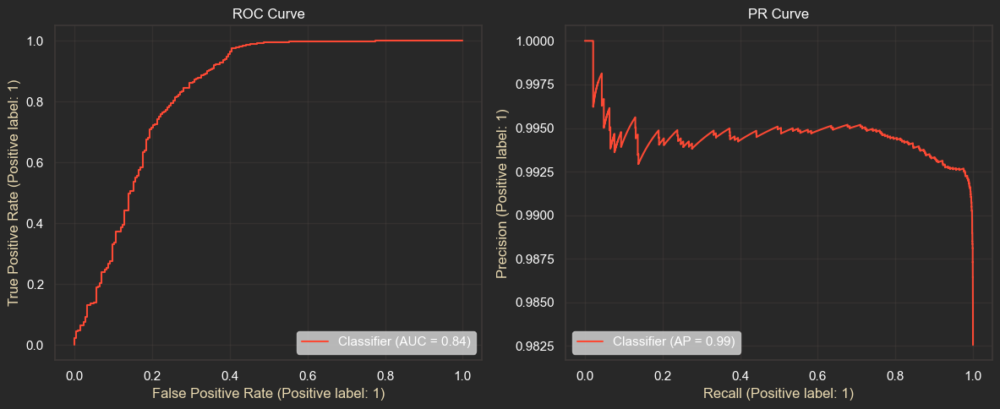

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_cat_v3, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_cat_v3, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [110]:
threshold_report(y_val, y_proba_cat_v3)

Threshold  F1         Recall     Precision 
0.50      0.993     0.996     0.991     
0.40      0.994     0.997     0.990     
0.30      0.994     0.998     0.989     
0.20      0.993     0.999     0.989     
0.10      0.993     0.999     0.987     


#### LightGBM v3

In [111]:
def objective(trial):
    params = {
        'n_estimators':trial.suggest_int('n_estimators',500,4000),
        'max_depth':trial.suggest_int('max_depth',1, 15),
        'learning_rate':trial.suggest_float('learning_rate',0.01, 1.0),
        'num_leaves':trial.suggest_int('num_leaves',30, 150),
        'min_child_samples':trial.suggest_int('min_child_samples',5, 60),
        'subsample':trial.suggest_float('subsample',0.1, 1.0),
        'colsample_bytree':trial.suggest_float('colsample_bytree',0.1, 1.0),
        'reg_alpha':trial.suggest_float('reg_alpha',0, 1.0),
        'reg_lambda':trial.suggest_int('reg_lambda',1, 10),
}

    model = LGBMClassifier(
        **params,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        verbose=0
    )
    model.fit(X_train, y_train)
    
    score = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    return score


study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective, n_trials=50, show_progress_bar=True)

[I 2026-07-28 13:34:22,044] A new study created in memory with name: no-name-e00b6bc3-7083-4d0b-ba7e-e8b71f62b703


  0%|          | 0/50 [00:00<?, ?it/s]

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [112]:
best_params_lgbm_v3 = study_lgb.best_params
print('Лучшие параметры:', study_lgb.best_params)
print('Лучший CV score:', study_lgb.best_value)

Лучшие параметры: {'n_estimators': 3800, 'max_depth': 14, 'learning_rate': 0.013605165608077003, 'num_leaves': 146, 'min_child_samples': 14, 'subsample': 0.309620991053872, 'colsample_bytree': 0.25643811226738256, 'reg_alpha': 0.00043578996524273883, 'reg_lambda': 7}
Лучший CV score: 0.8341081665981345


In [113]:
print("Метрики на валидационных данных:")
best_lgbm_v3 = LGBMClassifier(
    **best_params_lgbm_v3,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    verbose=0
)
best_lgbm_v3.fit(X_train,y_train)
y_pred_lgbm_v3 = best_lgbm_v3.predict(X_val)
y_proba_lgbm_v3 = best_lgbm_v3.predict_proba(X_val)[:, 1]

Метрики на валидационных данных:
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [114]:
model_metrics(y_val,y_pred_lgbm_v3, y_proba_lgbm_v3)

ROC-AUC : 0.8341
PR-AUC  : 0.9943
Gini    : 0.6682
Lift@10 : 1.0120
Lift@20 : 1.0128
Recall  : 0.9966


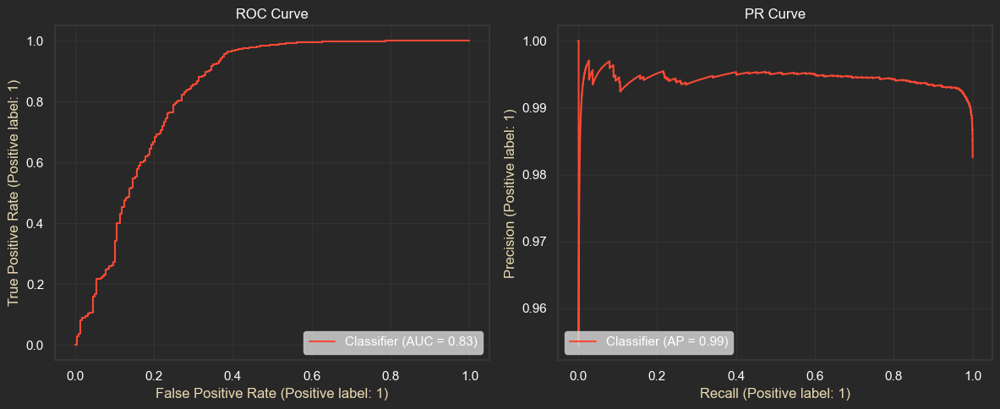

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_val, y_proba_lgbm_v3, ax=axes[0])
axes[0].set_title('ROC Curve')

# PR curve
PrecisionRecallDisplay.from_predictions(y_val, y_proba_lgbm_v3, ax=axes[1])
axes[1].set_title('PR Curve')

plt.tight_layout()
plt.show()

In [116]:
threshold_report(y_val, y_proba_lgbm_v3)

Threshold  F1         Recall     Precision 
0.50      0.993     0.997     0.989     
0.40      0.993     0.998     0.988     
0.30      0.993     0.999     0.987     
0.20      0.993     1.000     0.986     
0.10      0.992     1.000     0.984     


In [117]:
best_models_name = [
    "LightGBM",
    "LightGBM_v2",
    "LightGBM_v3",
    "CatBoost",
    "CatBoost_v2",
    "CatBoost_v3"
]
best_models_proba = [
        y_proba_lgb,
        y_proba_cat,
        y_proba_lgb_v2,
        y_proba_cat_v2,
        y_proba_lgbm_v3,
        y_proba_cat_v3
    ]
best_models_pred = [
    y_pred_lgb,
    y_pred_cat,
    y_pred_lgb_v2,
    y_pred_cat_v2,
    y_pred_lgbm_v3,    
    y_pred_cat_v3
]

def score_func(prediction,score_type,column_name):
    best_models_score = []
    
    for pred in prediction:
        score = float(score_type(y_val, pred))
        best_models_score.append(score)

    score_df = pd.DataFrame({'models_name':best_models_name,column_name:best_models_score})
    return score_df

roc_df = score_func(best_models_proba,roc_auc_score,"ROC_SCORE")
pr_df = score_func(best_models_proba,average_precision_score, "PR_SCORE")
precision_df = score_func(best_models_pred, precision_score, "PRECISION_SCORE")
recall_df = score_func(best_models_pred, recall_score, "RECALL_SCORE")

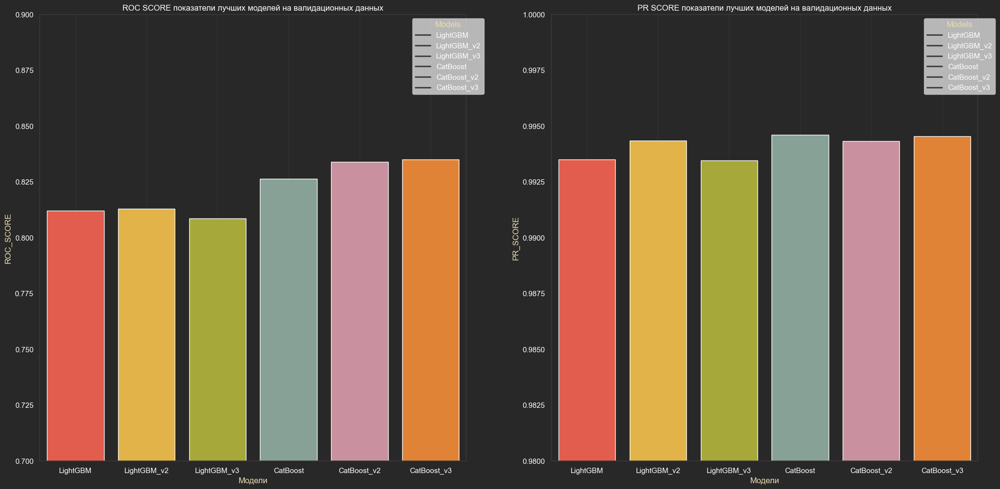

In [118]:
plt.figure(figsize=(25,12))
plt.subplot(1,2,1)
sns.barplot(data = roc_df, x = roc_df['models_name'], y = roc_df['ROC_SCORE'], palette=colorbox)
plt.ylim(0.7, 0.9)
plt.grid()
plt.title('ROC SCORE показатели лучших моделей на валидационных данных')
plt.xlabel('Модели')
plt.legend(title='Models', labels=best_models_name, bbox_to_anchor=(1.05, 1), loc='upper right')
plt.subplot(1,2,2)
sns.barplot(data = pr_df, x = pr_df['models_name'], y = pr_df['PR_SCORE'], palette=colorbox)
plt.ylim(0.98, 1.0)
plt.title('PR SCORE показатели лучших моделей на валидационных данных')
plt.xlabel('Модели')
plt.legend(title='Models', labels=best_models_name, bbox_to_anchor=(1.05, 1), loc='upper right')
plt.grid()
plt.show()

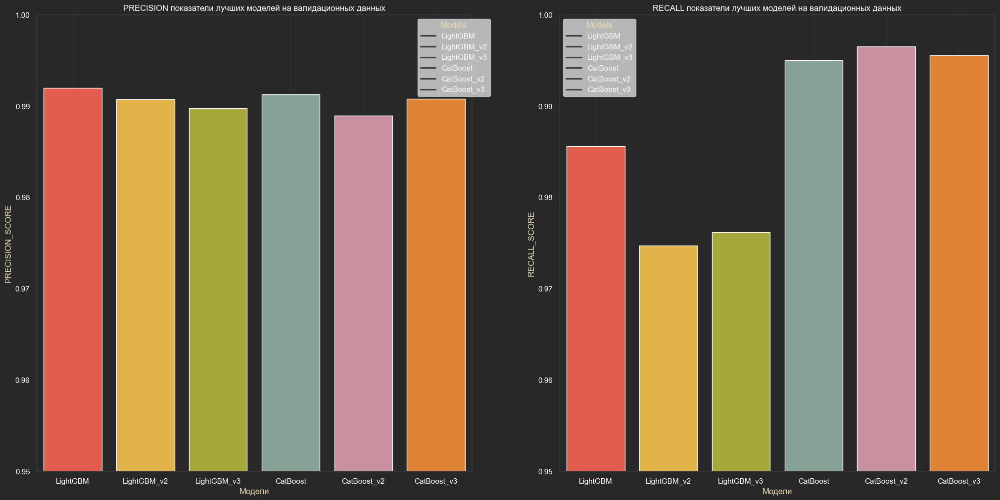

In [120]:
plt.figure(figsize=(25,12))
plt.subplot(1,2,1)
sns.barplot(
    data = precision_df, 
    x = precision_df['models_name'],
    y = precision_df['PRECISION_SCORE'],
    palette=colorbox
)
plt.ylim(0.95, 1.0)
plt.grid()
plt.title('PRECISION показатели лучших моделей на валидационных данных')
plt.xlabel('Модели')
plt.legend(title='Models', labels=best_models_name, bbox_to_anchor=(1.05, 1), loc='upper right')
plt.subplot(1,2,2)
sns.barplot(
    data = recall_df,
    x = recall_df['models_name'],
    y = recall_df['RECALL_SCORE'],
    palette=colorbox
)
plt.ylim(0.95, 1.0)
plt.title('RECALL показатели лучших моделей на валидационных данных')
plt.xlabel('Модели')
plt.legend(title='Models', labels=best_models_name, loc='upper left')
plt.grid()
plt.show()

CatBoost стабильно лучше LightGBM во всех версиях (0.826-0.835 vs 0.808-0.813). CatBoost_v3 - лучший результат (0.835). Внутри каждого семейства улучшение от версии к версии небольшое, но монотонное, поиск гипперпараметров дал прирост. LightGBM_v3 немного откатился относительно v2 (0.808 vs 0.813), возможно переобучение при дообучении.

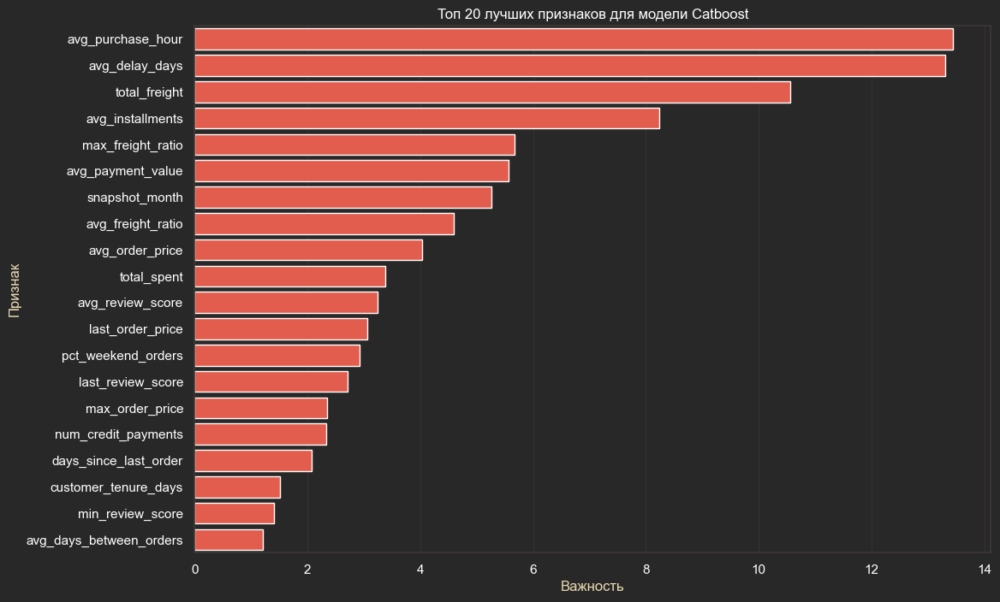

In [129]:
feature_names = train.drop(columns=['customer_unique_id', 'churn', 'snapshot_date']).columns.tolist()
importances = best_cat_v3.feature_importances_

fi_cat = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=fi_cat.head(20), x='importance', y='feature', color=colorbox[0])
plt.title('Топ 20 лучших признаков для модели Catboost')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()

Анализ важности признаков показал, что наибольшее влияние на прогноз оттока оказывают признаки, связанные с качеством доставки и покупательским поведением клиентов. Самыми значимыми признаками оказались среднее время оплаты (avg_purchase_hour) и среднее время опоздания доставки товаров(avg_delay_days), что указывает на сильное влияние логистики на вероятность ухода клиента. Также высокий вклад внесли стоимость доставки и среднея сумма рассрочки (total_freight, avg_installments, max_freight_ratio), средняя сумма оплаты (avg_payment_value), а также отдельные месяцы, что говорит о сезонности некоторых продаж(snapshot_month). Важными также оказались временные признаки, такие как средний час покупки (avg_purchase_hour) и месяц формирования снапшота (snapshot_month), отражающие особенности поведения клиентов и сезонность. Менее значимые признаки также учитываются моделью, однако их вклад в итоговый прогноз существенно ниже.

In [122]:
pred_test = best_lgbm_v3.predict(X_test)
proba_test = best_lgbm_v3.predict_proba(X_test)[:,1]

In [123]:
model_metrics(y_test, pred_test, proba_test)

ROC-AUC : 0.5619
PR-AUC  : 0.9883
Gini    : 0.1238
Lift@10 : 1.0056
Lift@20 : 1.0044
Recall  : 0.9980


In [124]:
threshold_report(y_test, proba_test)

Threshold  F1         Recall     Precision 
0.50      0.992     0.998     0.986     
0.40      0.992     0.999     0.986     
0.30      0.993     1.000     0.986     
0.20      0.993     1.000     0.986     
0.10      0.993     1.000     0.986     
